In [1]:
import os
import io
import contextlib
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
import scanpy as sc
from sklearn.metrics import roc_auc_score
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.cluster import KMeans

from tqdm.auto import tqdm

import crisp

sc.settings.verbosity = 0
logging.getLogger('scanpy').setLevel(logging.ERROR)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
from sklearn.decomposition import PCA

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
# --- Global font settings (consistent, larger, bold titles) ---
plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 20,
    "axes.titleweight": "bold",
    "axes.labelsize": 18,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 16,
    "legend.title_fontsize": 17,
    "figure.titlesize": 24,
    "figure.titleweight": "bold",
})


In [3]:
import importlib
import crisp, crisp.core, crisp.encode
# importlib.reload(crisp.simulate)
# importlib.reload(crisp.core)
# importlib.reload(crisp.encode)
# importlib.reload(crisp)

In [4]:
# â”€â”€ Shared utilities â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€


@contextlib.contextmanager
def _quiet():
    """Suppress stdout from compute_projection_similarity."""
    with io.StringIO() as buf, contextlib.redirect_stdout(buf):
        yield


def run_crisp(adata, k=15):
    """Encode both signals and return (global_spearman, mean_cell_spearman)."""
    crisp.encode_circular(adata, 'label_a', obsm_key='sig_a')
    crisp.encode_circular(adata, 'label_b', obsm_key='sig_b')
    with _quiet():
        score = crisp.compute_projection_similarity(adata, 'sig_a', 'sig_b', metric_A="knn", metric_B="knn")
    return float(score)

def circular_regression_global(a, b):
    """Goodness-of-fit of model b = a + phi. Returns mean(cos(residuals)) in [0, 1]."""
    phi_hat = np.arctan2(np.mean(np.sin(b - a)), np.mean(np.cos(b - a)))
    return float(np.mean(np.cos(b - a - phi_hat)))

In [5]:
# ── Shared constants ───────────────────────────────────────
N_CELLS  = 1000
N_GENES_A = 100
N_GENES_B = 100
N_SEEDS   = 5

# ── Score keys ───────────────────────────────────────────
GLOBAL_SCORE_KEY = "proj_mean_cell_pearson"   # adata.uns[GLOBAL_SCORE_KEY]
CELL_SCORE_KEY   = "proj_pearson_cell"     # adata.obs[CELL_SCORE_KEY]

In [6]:
import os
SAVE_DIR = os.path.normpath(os.path.join(os.getcwd(), "..", "cos_simulation_benchmark"))
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"Saving plots to: {SAVE_DIR}")

Saving plots to: /cs/labs/mornitzan/jeremies/processes_interactions/cos_simulation_benchmark_crisp_pack


In [7]:
def _cyclic_genes(angles, n_genes, std, noise, rng):
    n = len(angles)
    G = np.zeros((n, n_genes))
    for g in range(n_genes):
        peak = rng.uniform(0, 2 * np.pi)
        d = np.abs(angles - peak)
        G[:, g] = np.exp(-np.minimum(d, 2 * np.pi - d) ** 2 / (2 * std ** 2))
    return G + rng.normal(0, noise, G.shape)


def _centered_product_genes(angles_a, angles_b, n_genes, std, noise, rng):
    """AB interaction genes: (gauss(la) - mean) * (gauss(lb) - mean).

    Each gene peaks jointly at one (la, lb) combination. Because each factor
    is zero-mean, proj_A and proj_B both retain the joint signal, yielding a
    Spearman score higher than pure A, B, or C genes. In practice the score
    is well above zero but not close to 1 due to noise and partial permutation.
    """
    n = len(angles_a)
    G = np.zeros((n, n_genes))
    for g in range(n_genes):
        pa  = rng.uniform(0, 2 * np.pi)
        pb  = rng.uniform(0, 2 * np.pi)
        da  = np.minimum(np.abs(angles_a - pa), 2 * np.pi - np.abs(angles_a - pa))
        db  = np.minimum(np.abs(angles_b - pb), 2 * np.pi - np.abs(angles_b - pb))
        f   = np.exp(-da ** 2 / (2 * std ** 2))
        # f   -= f.mean()
        g_b = np.exp(-db ** 2 / (2 * std ** 2))
        # g_b -= g_b.mean()
        G[:, g] = f * g_b
    return G + rng.normal(0, noise, G.shape)


def _background_genes(n_cells, n_genes, std, noise, rng):
    """Genes C: cyclic genes on a fixed independent label, uncorrelated
    with label_a and label_b."""
    label_bg = np.random.default_rng(42).permutation(
        np.linspace(0, 2 * np.pi, n_cells, endpoint=False)
    )
    return _cyclic_genes(label_bg, n_genes, std, noise, rng)


def _unit_var(G):
    return G / (G.std(axis=0, keepdims=True) + 1e-8)


def simulate_cyclic_processes(
    n_cells, n_genes_A, n_genes_B, n_genes_AB,
    n_genes_background=0,
    noise=0.1, std=np.pi / 4, seed=None,
    perm_frac_b=0.0,
    label_noise=0.1,
):
    """Simulate gene expression from two cyclic interacting processes.

    Gene layout: n_genes_A (A) | n_genes_B (B) | n_genes_background (C) | n_genes_AB (AB)
    - A genes:  cyclic Gaussians driven by label_a
    - B genes:  cyclic Gaussians driven by label_b
    - C genes:  cyclic Gaussians driven by an independent background label
    - AB genes: centered-product (gauss(la)-mean)*(gauss(lb)-mean)

    Both labels are cyclic, with label_b = (label_a + random_phase) % 2pi.

    label_noise : std of wrapped Gaussian noise added to both labels before
                  gene generation (simulates imprecise phase measurement).
    """
    rng_genes = np.random.default_rng(seed)

    label_a = np.linspace(0, 2 * np.pi, n_cells, endpoint=False)
    phase   = rng_genes.uniform(0, 2 * np.pi)
    label_b = (label_a + phase) % (2 * np.pi)



    genes_A = _cyclic_genes(label_a, n_genes_A, std, noise, rng_genes)
    genes_B = _cyclic_genes(label_b, n_genes_B, std, noise, rng_genes)

    # Jointly permute B-genes and label_b for a fraction of cells
    permuted = np.zeros(n_cells, dtype=bool)
    if perm_frac_b > 0.0:
        k    = int(round(perm_frac_b * n_cells))
        idx  = rng_genes.choice(n_cells, size=k, replace=False)
        perm = rng_genes.permutation(k)
        genes_B[idx] = genes_B[idx][perm].copy()
        label_b      = label_b.copy()
        label_b[idx] = label_b[idx][perm].copy()
        permuted[idx] = True

    parts = [genes_A, genes_B]
    if n_genes_background > 0:
        parts.append(_background_genes(n_cells, n_genes_background, std, noise, rng_genes))
    if n_genes_AB > 0:
        parts.append(_centered_product_genes(
            label_a, label_b, n_genes_AB, std,
            noise=noise, rng=rng_genes))
    if label_noise > 0.0:
        label_a = (label_a + rng_genes.normal(0, label_noise, n_cells)) % (2 * np.pi)
        label_b = (label_b + rng_genes.normal(0, label_noise, n_cells)) % (2 * np.pi)
    gene_types = (
        ["A"] * n_genes_A +
        ["B"] * n_genes_B +
        (["C"] * n_genes_background if n_genes_background > 0 else []) +
        (["AB"] * n_genes_AB        if n_genes_AB > 0        else [])
    )
    adata = ad.AnnData(X=np.hstack(parts).astype(np.float32))
    adata.obs['label_a']  = label_a
    adata.obs['label_b']  = label_b
    adata.obs['permuted'] = permuted
    adata.var['gene_type'] = gene_types
    return adata

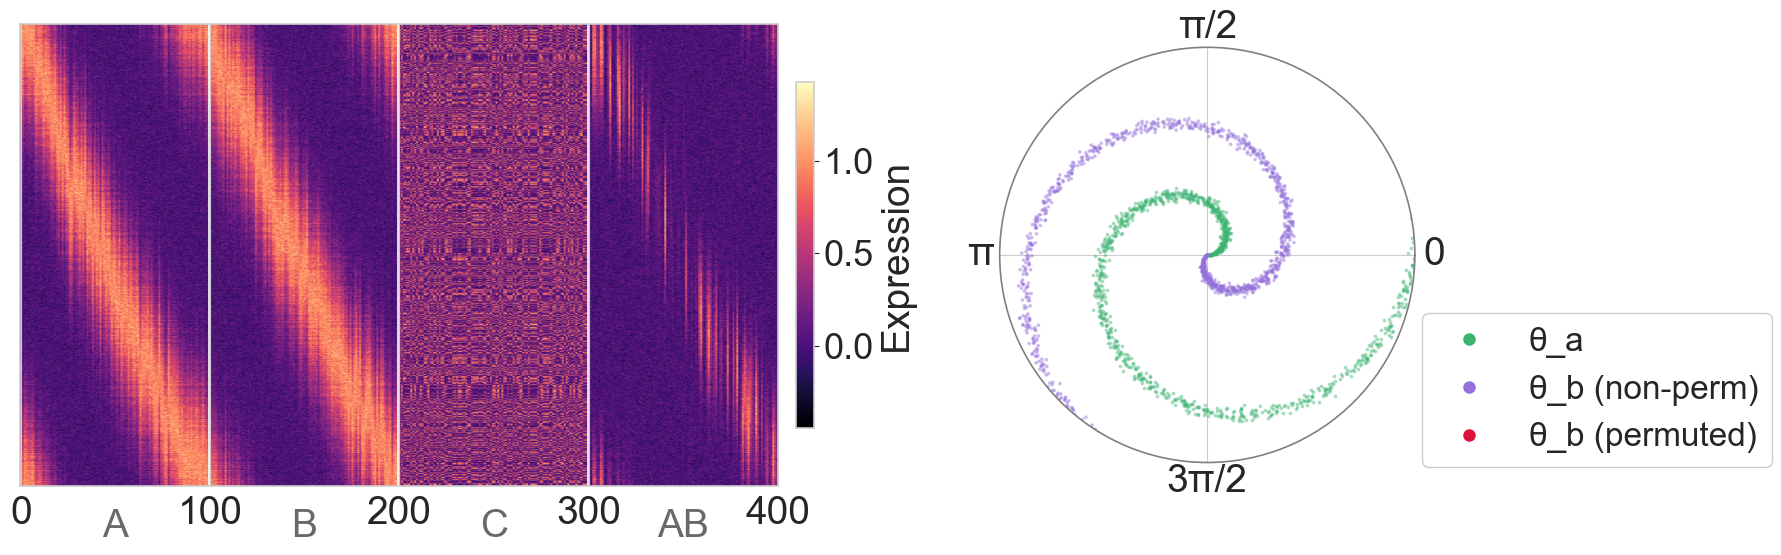

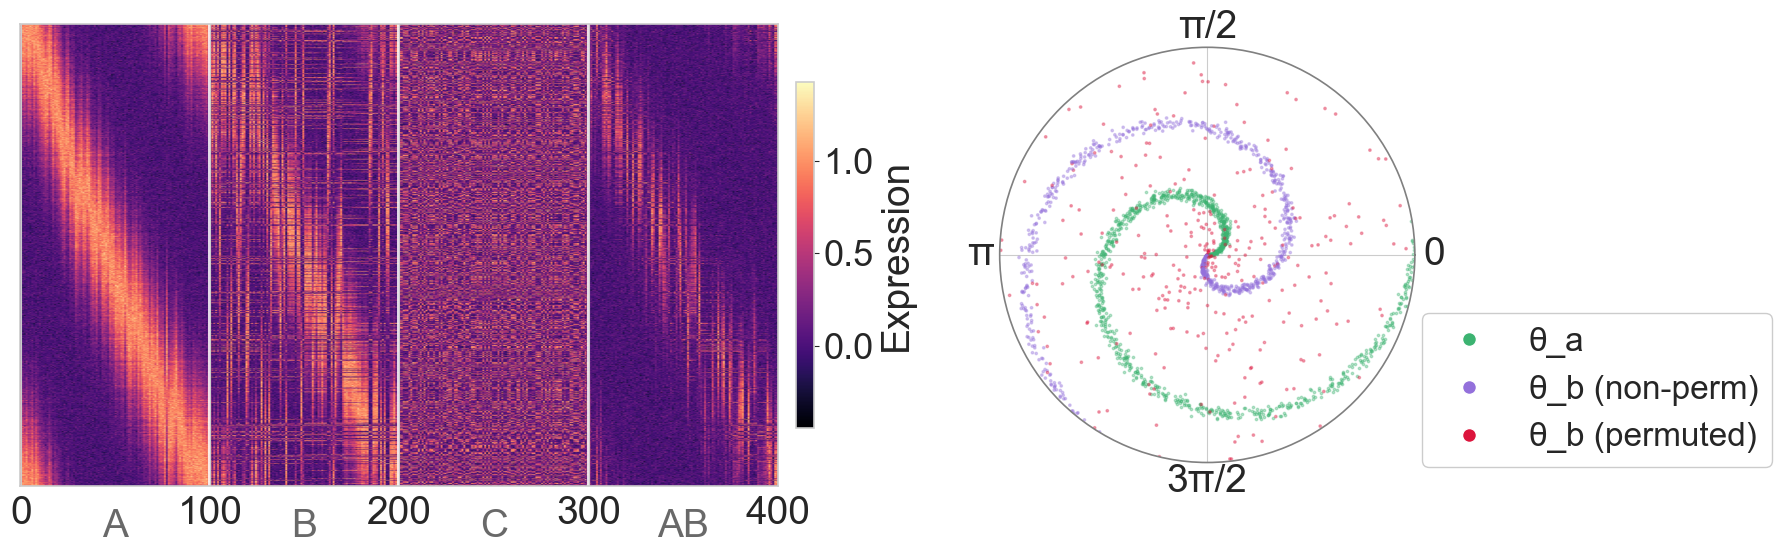

In [8]:
from matplotlib import gridspec
from matplotlib.lines import Line2D

settings = [
    {"n_AB": 100, "perm": 0.0, "title": ""},
    {"n_AB": 100, "perm": 0.3, "title": ""},
]

adatas_sorted = {}

for s in settings:
    adata = simulate_cyclic_processes(
        N_CELLS, 100, 100, s["n_AB"],
        n_genes_background=100,
        noise=0.1, seed=0,
        perm_frac_b=s["perm"],
        label_noise=0.1
    )
    la       = adata.obs["label_a"].values
    lb       = adata.obs["label_b"].values
    permuted = adata.obs["permuted"].values.astype(bool)
    X        = adata.X if not hasattr(adata.X, "toarray") else adata.X.toarray()

    sort_idx = np.argsort(la)
    X_rows = X[sort_idx]

    boundaries = [0, 100, 200, 300, X_rows.shape[1]]
    ordered_blocks = []
    for start, end in zip(boundaries[:-1], boundaries[1:]):
        block = X_rows[:, start:end]
        order = np.argsort(np.argmax(block, axis=0), kind="stable")
        ordered_blocks.append(start + order)
    gene_order = np.concatenate(ordered_blocks)
    X_display = X_rows[:, gene_order]

    # save adata with the display ordering applied
    adata_sorted = adata[sort_idx, :][:, gene_order].copy()
    adatas_sorted[s["perm"]] = adata_sorted

    circ_reg = circular_regression_global(la, lb)

    fig = plt.figure(figsize=(18, 6), facecolor="white")
    gs  = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[2.2, 1], wspace=0.1)

    ax_hm = fig.add_subplot(gs[0, 0])
    im = ax_hm.imshow(X_display, aspect="auto", cmap="magma", origin="upper")
    for xv in [100, 200, 300]:
        ax_hm.axvline(xv - 0.5, color="white", lw=1.2)
    ax_hm.set_xticks([0, 100, 200, 300, 400])
    ax_hm.set_xticklabels(["0", "100", "200", "300", "400"], fontsize=28)
    for xpos, gname in zip([0.125, 0.375, 0.625, 0.875], ["A", "B", "C", "AB"]):
        ax_hm.text(xpos, -0.05, gname, transform=ax_hm.transAxes,
                   ha="center", va="top", fontsize=28, color="dimgray")
    ax_hm.set_yticks([])
    cbar = fig.colorbar(im, ax=ax_hm, shrink=0.75, pad=0.02)
    cbar.set_label("Expression", fontsize=28)
    cbar.ax.tick_params(labelsize=26)

    ax_pol = fig.add_subplot(gs[0, 1], projection="polar")
    ax_pol.set_facecolor("white")
    ax_pol.spines["polar"].set_edgecolor("gray")
    ax_pol.spines["polar"].set_linewidth(1.2)
    radii = np.arange(N_CELLS) / N_CELLS
    ax_pol.scatter(la, radii, c="mediumseagreen", s=3, alpha=0.35, zorder=2)
    colors_b = np.where(permuted, "crimson", "mediumpurple")
    ax_pol.scatter(lb, radii, c=colors_b, s=3, alpha=0.35, zorder=2)
    ax_pol.set_rmin(0)
    ax_pol.set_rmax(1)
    ax_pol.set_rticks([])
    ax_pol.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2])
    ax_pol.set_xticklabels(["0", "π/2", "π", "3π/2"], fontsize=28)
    legend_handles = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor="mediumseagreen",
               markersize=10, label="θ_a"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="mediumpurple",
               markersize=10, label="θ_b (non-perm)"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="crimson",
               markersize=10, label="θ_b (permuted)"),
    ]
    ax_pol.legend(handles=legend_handles, fontsize=24,
                  loc="lower right", bbox_to_anchor=(1.9, -0.05),
                  facecolor="white", framealpha=1.0)

    # fig.suptitle(s["title"], fontsize=22)
    perm_tag = str(s["perm"]).replace(".", "")
    fname = f"01_heatmap_spiral_perm{perm_tag}.png"
    plt.savefig(os.path.join(SAVE_DIR, fname), dpi=150, bbox_inches="tight")
    plt.show()

# adatas_sorted[0.0] and adatas_sorted[0.3] hold the reordered AnnData objects

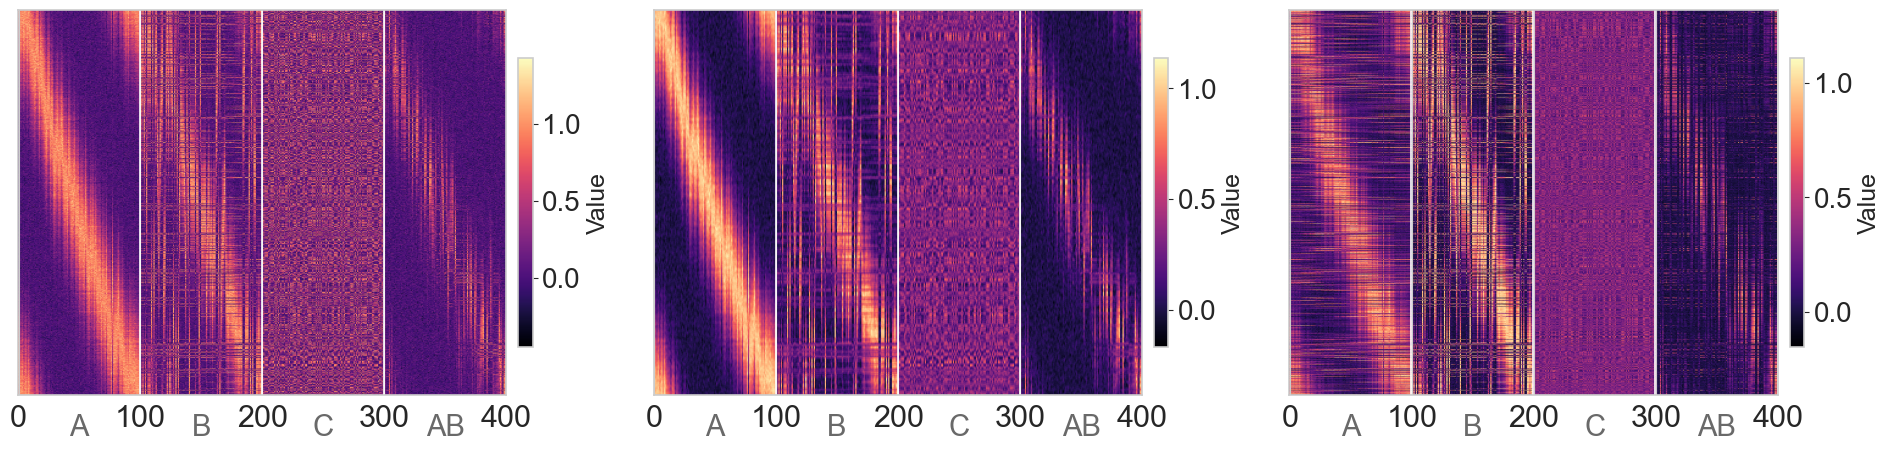

In [9]:
# Heatmaps of X, proj_A and proj_B for perm=0.3 (cells and genes already sorted)
adata_s = adatas_sorted[0.3].copy()

crisp.encode_circular(adata_s, "label_a", obsm_key="sig_a")
crisp.encode_circular(adata_s, "label_b", obsm_key="sig_b")
with _quiet():
    crisp.compute_projection_similarity(adata_s, "sig_a", "sig_b", metric_A="knn", metric_B="knn", store_projections=True)

X_s      = adata_s.X if not hasattr(adata_s.X, "toarray") else adata_s.X.toarray()
proj_A_s = adata_s.layers["proj_A"]
proj_B_s = adata_s.layers["proj_B"]

fig, axes = plt.subplots(1, 3, figsize=(24, 5))
fig.subplots_adjust(wspace=0.08)

for ax, mat, title in [
    (axes[0], X_s,      "X  (original expression)"),
    (axes[1], proj_A_s, r"proj$_A$"),
    (axes[2], proj_B_s, r"proj$_B$"),
]:
    im = ax.imshow(mat, aspect="auto", cmap="magma", origin="upper")
    for xv in [100, 200, 300]:
        ax.axvline(xv - 0.5, color="white", lw=1.2)
    ax.set_xticks([0, 100, 200, 300, 400])
    ax.set_xticklabels(["0", "100", "200", "300", "400"], fontsize=22)
    for xpos, gname in zip([0.125, 0.375, 0.625, 0.875], ["A", "B", "C", "AB"]):
        ax.text(xpos, -0.05, gname, transform=ax.transAxes,
                ha="center", va="top", fontsize=21, color="dimgray")
    ax.set_yticks([])
    cbar = fig.colorbar(im, ax=ax, shrink=0.75, pad=0.02)
    cbar.set_label("Value")
    # ax.set_title(title, fontsize=18)

# plt.suptitle("", fontsize=19)
plt.savefig(os.path.join(SAVE_DIR, "01b_heatmap_projections_perm03.png"),
            dpi=150, bbox_inches="tight")
plt.show()

In [10]:
try:
    from sift import SiFT
except ImportError:
    from sift._sift import SiFT


def _resolve_n_nbrs(signal_key, n_neighbors, categorical_obs_keys, adata):
    if not categorical_obs_keys:
        return n_neighbors
    obs_key = signal_key
    if signal_key not in categorical_obs_keys:
        for prefix in ("onehot_", "circular_"):
            if signal_key.startswith(prefix):
                candidate = signal_key[len(prefix):]
                if candidate in categorical_obs_keys:
                    obs_key = candidate
                    break
        else:
            return n_neighbors
    if obs_key not in adata.obs:
        raise KeyError(f"categorical_obs_keys: '{obs_key}' not found in adata.obs")
    return int(adata.obs[obs_key].value_counts().min())


def plot_sift_kernel(
    adata,
    signal_key,
    groupby,
    sort_by=None,
    n_neighbors=15,
    categorical_obs_keys=None,
    n_ticks=6,
    subset_obs=None,
    figsize=(7, 6),
    cmap="Blues",
    ax=None,
    save_path=None,
):
    """
    sort_by : str, optional
        obs column used to order cells on the axes. Defaults to groupby.
        Set to a different column (e.g. "label_a") to fix a common ordering
        across multiple kernel plots while using groupby only for tick labels.
    """
    bdata = adata.copy()
    if subset_obs is not None:
        for col, val in subset_obs.items():
            bdata = bdata[bdata.obs[col] == val].copy()

    n_neighbors = _resolve_n_nbrs(signal_key, n_neighbors, categorical_obs_keys, bdata)

    sort_col = sort_by if sort_by is not None else groupby
    try:
        sort_idx = np.argsort(bdata.obs[sort_col].values.astype(float))
    except (ValueError, TypeError):
        sort_idx = np.argsort(bdata.obs[sort_col].astype(str).values)
    bdata = bdata[sort_idx].copy()

    sft = SiFT(bdata, kernel_key=signal_key, metric="knn", n_neighbors=n_neighbors)
    raw_k = sft._kernel(**sft._kernel_containers)
    K = raw_k.toarray() if hasattr(raw_k, "toarray") else np.array(raw_k)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    im = ax.imshow(K, cmap=cmap, aspect="auto", interpolation="none", vmin=0)
    plt.colorbar(im, ax=ax, shrink=0.8, label="Kernel weight")

    labels = bdata.obs[groupby].values
    try:
        labels = labels.astype(float)
    except (ValueError, TypeError):
        pass

    unique_labels, counts = np.unique(labels, return_counts=True)
    is_continuous = len(unique_labels) > max(20, bdata.n_obs / 10)

    if is_continuous:
        tick_pos = np.linspace(0, bdata.n_obs - 1, n_ticks, dtype=int)
        ax.set_xticks(tick_pos)
        ax.set_xticklabels([f"{labels[p]:.2f}" for p in tick_pos],
                           rotation=45, ha="right", fontsize=17)
        ax.set_yticks(tick_pos)
        ax.set_yticklabels([f"{labels[p]:.2f}" for p in tick_pos], fontsize=17)
    else:
        midpoints  = np.cumsum(counts) - counts / 2
        boundaries = np.cumsum(counts)[:-1]
        for b in boundaries:
            ax.axvline(b - 0.5, color="red", linewidth=0.8, alpha=0.5)
            ax.axhline(b - 0.5, color="red", linewidth=0.8, alpha=0.5)
        ax.set_xticks(midpoints)
        ax.set_xticklabels([f"{v:.2f}" if isinstance(v, float) else v for v in unique_labels],
                           rotation=45, ha="right", fontsize=17)
        ax.set_yticks(midpoints)
        ax.set_yticklabels([f"{v:.2f}" if isinstance(v, float) else v for v in unique_labels],
                           fontsize=17)

    sort_note = f", sorted by '{sort_col}'" if sort_by is not None else ""
    # ax.set_title(
        # f"SIFT kernel  |  signal: '{signal_key}'groupby: '{groupby}'{sort_note}  "
        # f"(n={bdata.n_obs}, k={n_neighbors})",
        # fontsize=16,
    # )
    if save_path:
        ax.figure.savefig(save_path, bbox_inches="tight", dpi=150)
    return ax

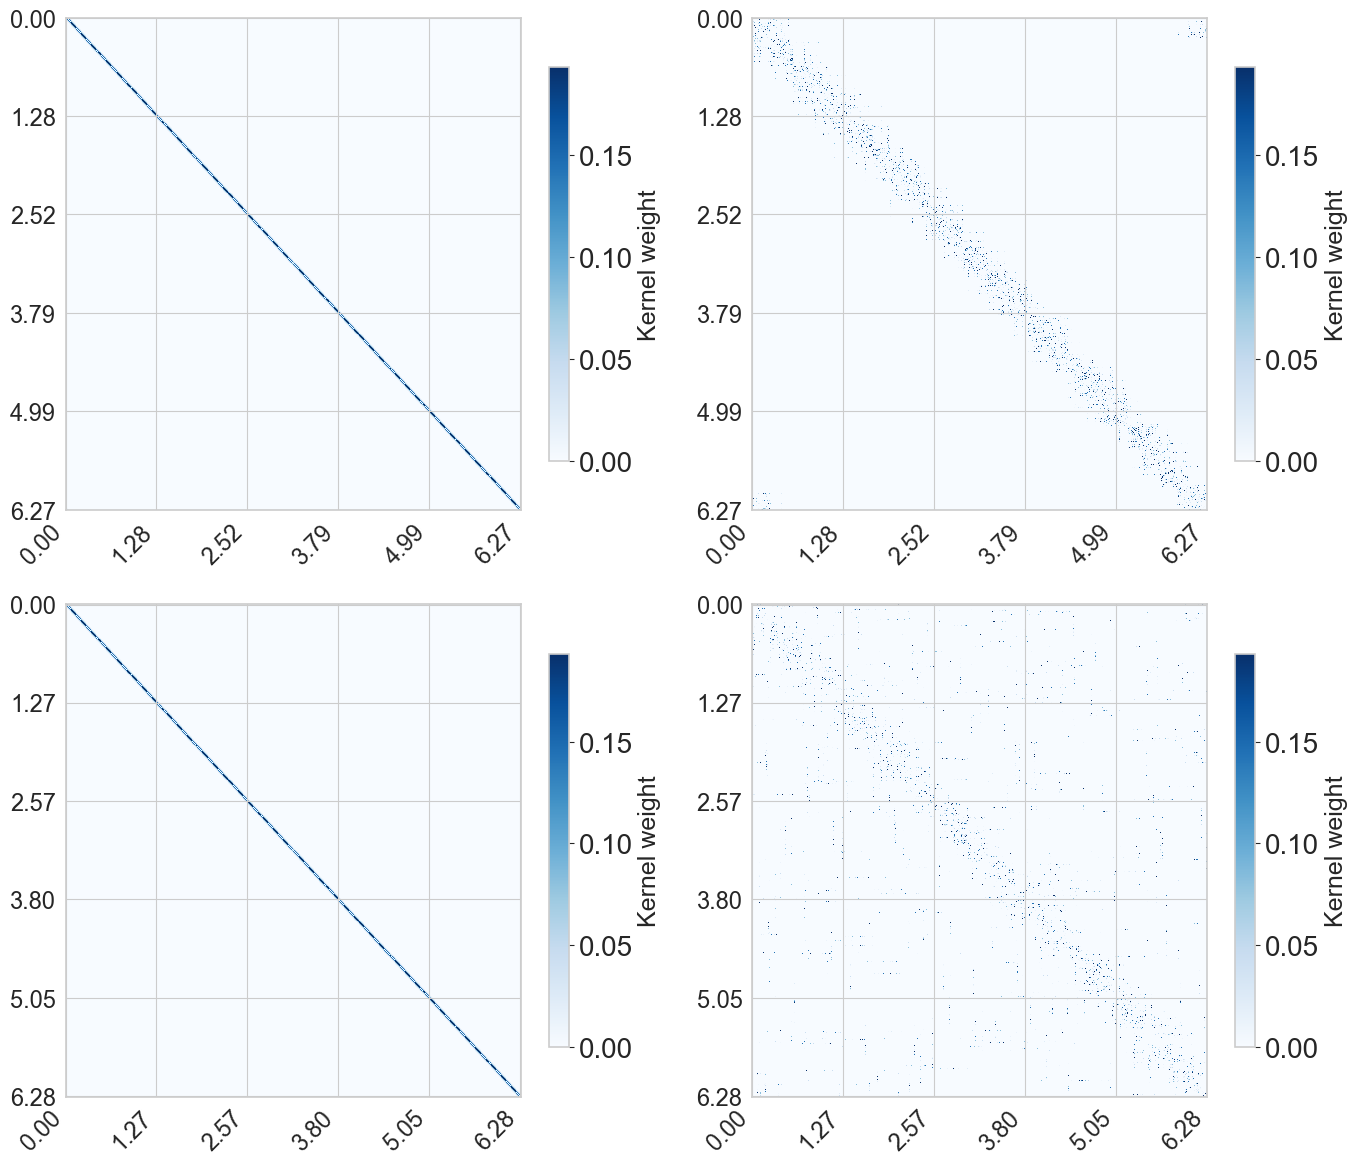

In [11]:
# SIFT kernels for perm=0.0 and perm=0.3, cells always sorted by label_a
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for row_i, (perm, perm_label) in enumerate([(0.0, "perm=0.0"), (0.3, "perm=0.3")]):
    bdata = adatas_sorted[perm].copy()
    crisp.encode_circular(bdata, "label_a", obsm_key="sig_a")
    crisp.encode_circular(bdata, "label_b", obsm_key="sig_b")

    plot_sift_kernel(bdata, signal_key="sig_a", groupby="label_a", sort_by="label_a", ax=axes[row_i, 0])
    plot_sift_kernel(bdata, signal_key="sig_b", groupby="label_a", sort_by="label_a", ax=axes[row_i, 1])

# plt.suptitle("SIFT kernels — simulation (perm=0.0 vs perm=0.3)", fontsize=18)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "01c_sift_kernels.png"), dpi=150, bbox_inches="tight")
plt.show()

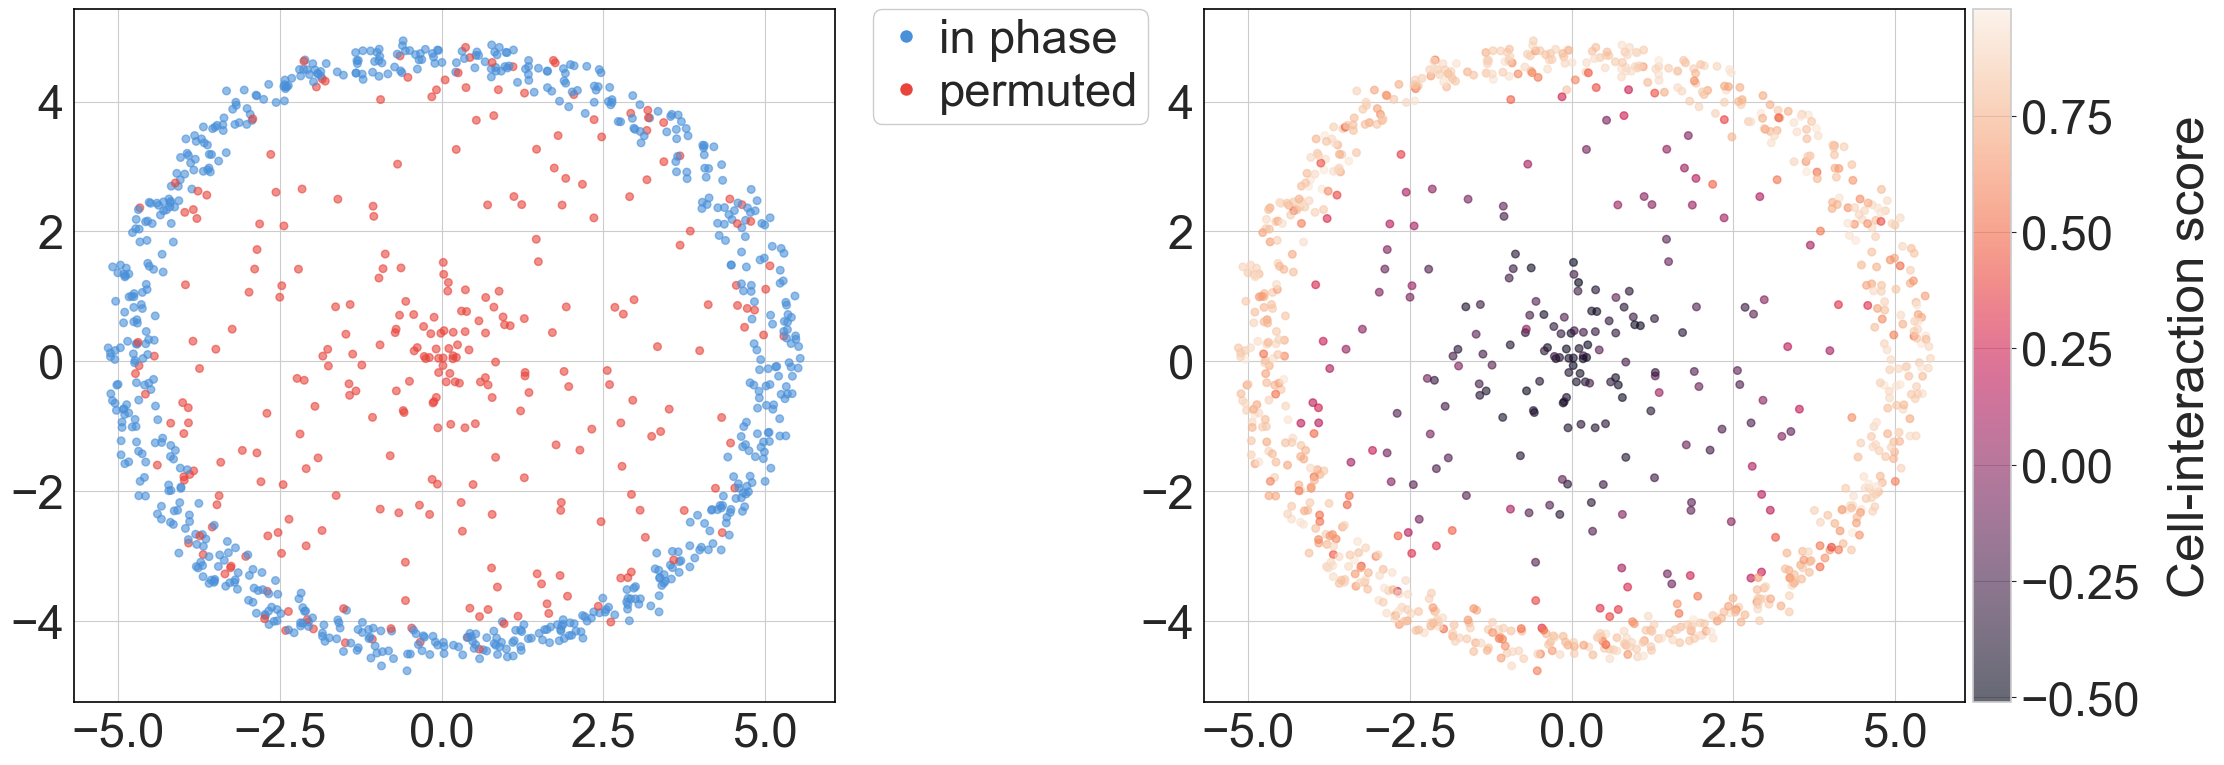

In [12]:
# PCA: 100A | 100B | 100C | 100AB, perm_frac_b=0.3
adata_pca = simulate_cyclic_processes(
    N_CELLS, 100, 100, 100,
    n_genes_background=100,
    noise=0.1,
    perm_frac_b=0.3,
)

crisp.encode_circular(adata_pca, "label_a", obsm_key="sig_a")
crisp.encode_circular(adata_pca, "label_b", obsm_key="sig_b")
with _quiet():
    crisp.compute_projection_similarity(adata_pca, "sig_a", "sig_b", metric_A="knn", metric_B="knn")

X_pca_vis = adata_pca.X if not hasattr(adata_pca.X, "toarray") else adata_pca.X.toarray()
coords_pca = PCA(n_components=2).fit_transform(X_pca_vis)
permuted_pca    = adata_pca.obs["permuted"].values.astype(bool)
cell_scores_pca = adata_pca.obs[CELL_SCORE_KEY].values

from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1 import make_axes_locatable

FSIZE = 36

fig, axes = plt.subplots(1, 2, figsize=(25, 9), facecolor="white")
fig.subplots_adjust(wspace=0.4)

for ax in axes:
    ax.set_facecolor("white")
    for spine in ax.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(1.2)
    ax.tick_params(labelsize=FSIZE - 2)

make_axes_locatable(axes[0]).append_axes("right", size="5%", pad=0.08).axis("off")

# ── left: binary permuted label ──────────────────────────────────────────
binary_colors = np.where(permuted_pca, "#e8453c", "#4a90d9")
axes[0].scatter(coords_pca[:, 0], coords_pca[:, 1],
                c=binary_colors, s=30, alpha=0.6)
# axes[0].set_title("Permuted label", fontsize=FSIZE + 1)
# axes[0].set_xlabel("PC1", fontsize=FSIZE)
# axes[0].set_ylabel("PC2", fontsize=FSIZE)

legend_handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#4a90d9", markersize=10, label="in phase"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#e8453c", markersize=10, label="permuted"),
]
axes[0].legend(handles=legend_handles, fontsize=FSIZE - 2, loc="upper left",
               bbox_to_anchor=(1.05, 1), borderaxespad=0,
               frameon=True, facecolor="white", framealpha=1.0, handletextpad=0.2, borderpad=0.2,
               labelspacing=0.2, handlelength=1.0)

# ── right: continuous cell score ─────────────────────────────────────────
divider = make_axes_locatable(axes[1])
cax = divider.append_axes("right", size="5%", pad=0.08)

sc1 = axes[1].scatter(coords_pca[:, 0], coords_pca[:, 1],
                      c=cell_scores_pca, cmap="rocket", s=30, alpha=0.6)
cb = fig.colorbar(sc1, cax=cax)
cb.set_label("Cell-interaction score", fontsize=FSIZE + 1, labelpad=20)
cb.ax.tick_params(labelsize=FSIZE - 2)
# axes[1].set_title("Cell-interaction score", fontsize=FSIZE + 1)
# axes[1].set_xlabel("PC1", fontsize=FSIZE)
# axes[1].set_ylabel("PC2", fontsize=FSIZE)

# plt.suptitle("", fontsize=FSIZE)
plt.savefig(os.path.join(SAVE_DIR, "02_pca_permuted_cellscore.png"), dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

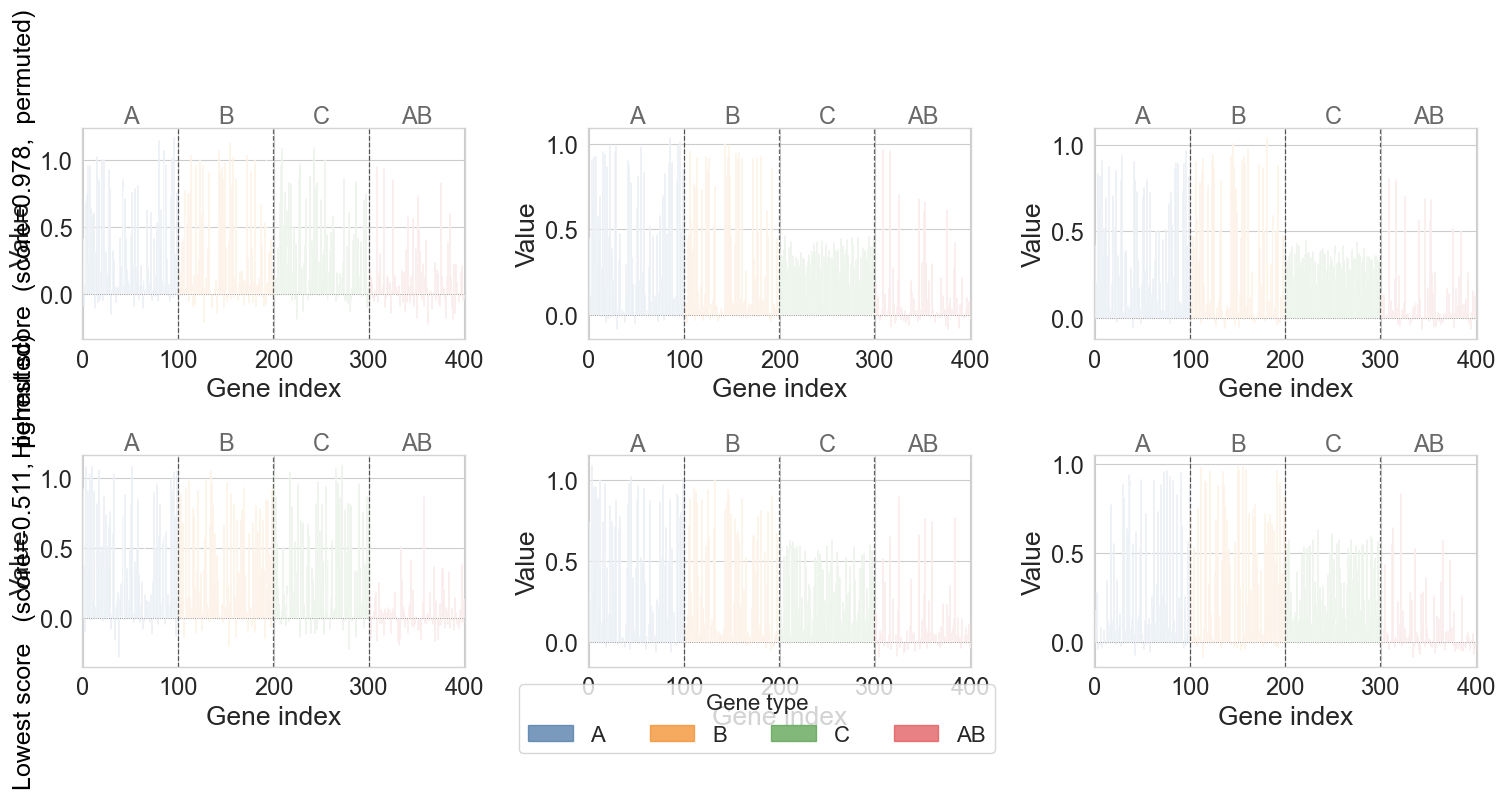

In [13]:
# Rerun with store_projections=True to get layers
with _quiet():
    crisp.compute_projection_similarity(adata_pca, "sig_a", "sig_b",  metric_A="knn", metric_B="knn", store_projections=True)

X_all   = adata_pca.X if not hasattr(adata_pca.X, "toarray") else adata_pca.X.toarray()
proj_A_all = adata_pca.layers["proj_A"]   # (n_cells, n_genes)
proj_B_all = adata_pca.layers["proj_B"]   # (n_cells, n_genes)

idx_high = int(np.argmax(cell_scores_pca))
idx_low  = int(np.argmin(cell_scores_pca))

gene_boundaries = [0, 100, 200, 300, 400]
gene_labels     = ["A", "B", "C", "AB"]
gene_colors     = ["#4e79a7", "#f28e2b", "#59a14f", "#e15759"]

cells_to_plot = [
    (idx_high, f"Highest score  (score={cell_scores_pca[idx_high]:.3f},  "
               f"{'permuted' if permuted_pca[idx_high] else 'non-permuted'})"),
    (idx_low,  f"Lowest score   (score={cell_scores_pca[idx_low]:.3f},  "
               f"{'permuted' if permuted_pca[idx_low] else 'non-permuted'})"),
]

col_specs = [
    (X_all,      "Gene expression X"),
    (proj_A_all, r"proj$_A$  =  X $-$ SIFT(X|A)"),
    (proj_B_all, r"proj$_B$  =  X $-$ SIFT(X|B)"),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 7), facecolor="white")
fig.subplots_adjust(hspace=0.55, wspace=0.32)

gene_idx = np.arange(400)

for row_i, (cell_idx, cell_title) in enumerate(cells_to_plot):
    for col_i, (data_all, col_title) in enumerate(col_specs):
        ax = axes[row_i, col_i]
        ax.set_facecolor("white")
        for spine in ax.spines.values():
            spine.set_edgecolor("lightgray")
            spine.set_linewidth(1.0)

        vals = data_all[cell_idx]
        for b_start, b_end, g_label, g_color in zip(
            gene_boundaries[:-1], gene_boundaries[1:], gene_labels, gene_colors
        ):
            ax.bar(gene_idx[b_start:b_end], vals[b_start:b_end],
                   color=g_color, alpha=0.75, width=1.0)

        for xv in gene_boundaries[1:-1]:
            ax.axvline(xv - 0.5, color="black", lw=0.9, ls="--", alpha=0.6)
        ax.axhline(0, color="gray", lw=0.6, ls=":")

        for xpos, g_label in zip([50, 150, 250, 350], gene_labels):
            ax.text(xpos, ax.get_ylim()[1] if col_i == 0 else vals.max() * 1.05,
                    g_label, ha="center", va="bottom", fontsize=17, color="dimgray")

        ax.set_xlim(-1, 401)
        ax.set_xlabel("Gene index", fontsize=19)
        ax.set_ylabel("Value", fontsize=19)
        ax.tick_params(labelsize=17)

        if row_i == 0:
            pass
            # ax.set_title(col_title, fontsize=17, pad=6)
        if col_i == 0:
            ax.annotate(cell_title, xy=(-0.12, 0.5), xycoords="axes fraction",
                        fontsize=18, rotation=90, va="center", ha="right",
                        color="black")

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=gene_colors[i], alpha=0.75, label=gene_labels[i])
    for i in range(4)
]
fig.legend(handles=legend_handles, title="Gene type", fontsize=16, title_fontsize=16,
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.03), frameon=True)

# plt.suptitle("Gene expression and projections — highest vs lowest score cells",
             # fontsize=19, y=1.01)
plt.savefig(os.path.join(SAVE_DIR, "02c_extreme_cells_projections.png"),
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

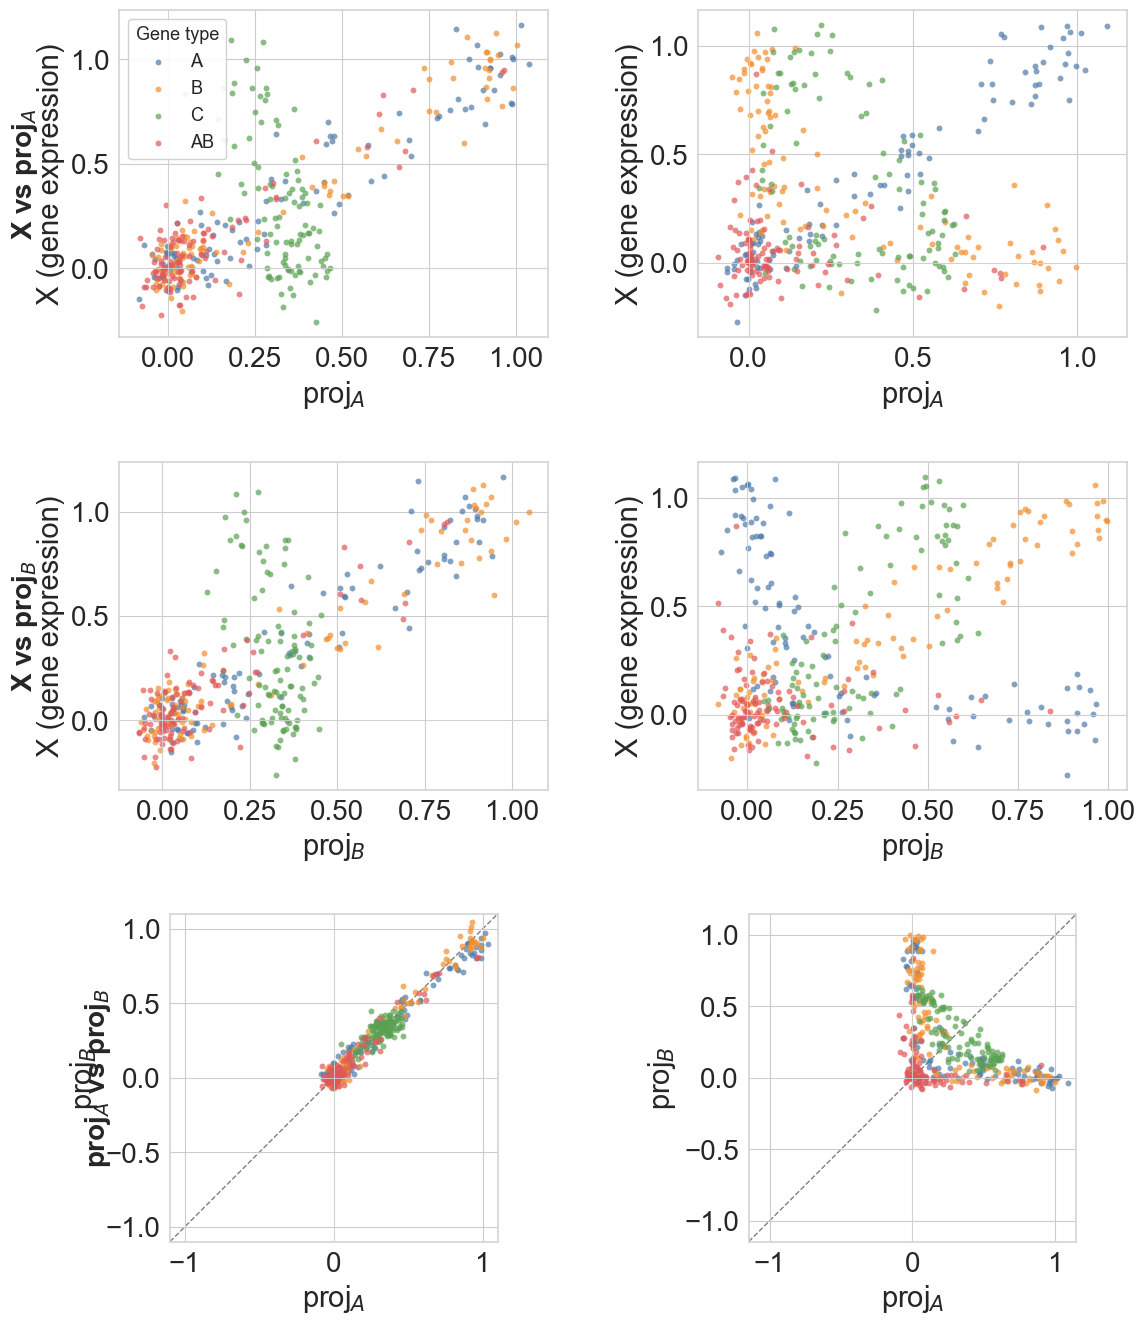

In [14]:
# 3x2 figure: rows = (X vs proj_A, X vs proj_B, proj_A vs proj_B), cols = (high, low)
gene_type_arr = adata_pca.var["gene_type"].values

fig, axes = plt.subplots(3, 2, figsize=(13, 16), facecolor="white")
fig.subplots_adjust(hspace=0.38, wspace=0.35)

def _style_ax(ax):
    ax.set_facecolor("white")
    for spine in ax.spines.values():
        spine.set_edgecolor("lightgray")

def _scatter_by_type(ax, x_vals, y_vals, add_legend=False):
    for g_label, g_color in zip(gene_labels, gene_colors):
        mask = gene_type_arr == g_label
        ax.scatter(x_vals[mask], y_vals[mask], c=g_color, s=18, alpha=0.7,
                   label=g_label, linewidths=0)
    ax.axhline(0, color="lightgray", lw=0.6)
    ax.axvline(0, color="lightgray", lw=0.6)
    if add_legend:
        ax.legend(title="Gene type", fontsize=13, title_fontsize=13,
                  loc="upper left", frameon=True, framealpha=0.9)

row_labels = [r"X vs proj$_A$", r"X vs proj$_B$", r"proj$_A$ vs proj$_B$"]

for col_i, (cell_idx, cell_title) in enumerate(cells_to_plot):
    pA = proj_A_all[cell_idx]
    pB = proj_B_all[cell_idx]
    x_expr = X_all[cell_idx]

    # row 0: X vs proj_A
    ax = axes[0, col_i]
    _style_ax(ax)
    _scatter_by_type(ax, pA, x_expr, add_legend=(col_i == 0))
    ax.set_xlabel(r"proj$_A$", fontsize=21)
    ax.set_ylabel("X (gene expression)", fontsize=21)
    # ax.set_title(cell_title, fontsize=14)

    # row 1: X vs proj_B
    ax = axes[1, col_i]
    _style_ax(ax)
    _scatter_by_type(ax, pB, x_expr)
    ax.set_xlabel(r"proj$_B$", fontsize=21)
    ax.set_ylabel("X (gene expression)", fontsize=21)

    # row 2: proj_A vs proj_B
    ax = axes[2, col_i]
    _style_ax(ax)
    _scatter_by_type(ax, pA, pB)
    lim = max(np.abs(pA).max(), np.abs(pB).max()) * 1.05
    ax.plot([-lim, lim], [-lim, lim], color="gray", lw=1.0, ls="--", zorder=0)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel(r"proj$_A$", fontsize=21)
    ax.set_ylabel(r"proj$_B$", fontsize=21)
    ax.set_aspect("equal")

for row_i, row_label in enumerate(row_labels):
    axes[row_i, 0].annotate(row_label, xy=(-0.22, 0.5), xycoords="axes fraction",
                             fontsize=20, rotation=90, va="center", ha="center",
                             fontweight="bold")

# plt.suptitle("Gene expression vs projections — highest vs lowest score cells",
             # fontsize=17, y=1.01)
plt.savefig(os.path.join(SAVE_DIR, "02d_X_vs_proj_extreme_cells.png"),
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

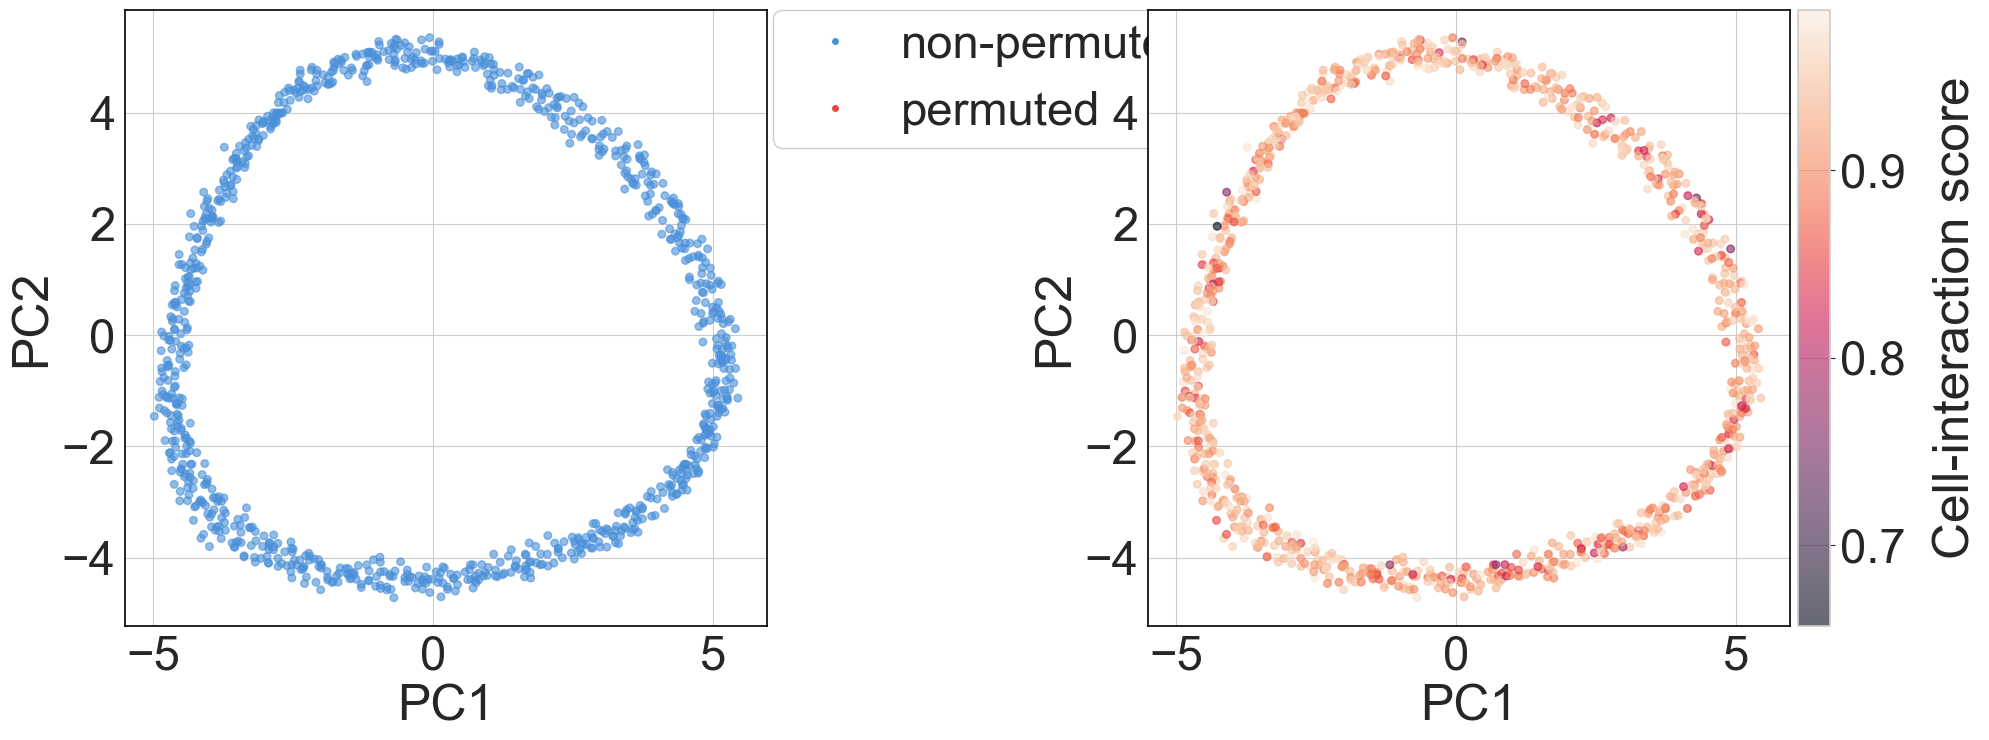

In [15]:
# PCA: 100A | 100B | 100C | 100AB, perm_frac_b=0.0
FSIZE = 36
adata_pca0 = simulate_cyclic_processes(
    N_CELLS, 100, 100, 100,
    n_genes_background=100,
    noise=0.1,
    perm_frac_b=0.0,
)

crisp.encode_circular(adata_pca0, "label_a", obsm_key="sig_a")
crisp.encode_circular(adata_pca0, "label_b", obsm_key="sig_b")
with _quiet():
    crisp.compute_projection_similarity(adata_pca0, "sig_a", "sig_b", metric_A="knn", metric_B="knn")

X_pca_vis0 = adata_pca0.X if not hasattr(adata_pca0.X, "toarray") else adata_pca0.X.toarray()
coords_pca0 = PCA(n_components=2).fit_transform(X_pca_vis0)
permuted_pca0    = adata_pca0.obs["permuted"].values.astype(bool)
cell_scores_pca0 = adata_pca0.obs[CELL_SCORE_KEY].values

fig, axes = plt.subplots(1, 2, figsize=(22, 8), facecolor="white")
fig.subplots_adjust(wspace=0.5)

for ax in axes:
    ax.set_facecolor("white")
    for spine in ax.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(1.2)
    ax.tick_params(labelsize=FSIZE - 2)

make_axes_locatable(axes[0]).append_axes("right", size="5%", pad=0.08).axis("off")

binary_colors0 = np.where(permuted_pca0, "#e8453c", "#4a90d9")
axes[0].scatter(coords_pca0[:, 0], coords_pca0[:, 1],
                c=binary_colors0, s=30, alpha=0.6)
# axes[0].set_title("Permuted label", fontsize=FSIZE + 1)
axes[0].set_xlabel("PC1", fontsize=FSIZE)
axes[0].set_ylabel("PC2", fontsize=FSIZE)

legend_handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#4a90d9", markersize=6, label="non-permuted"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#e8453c", markersize=6, label="permuted"),
]
axes[0].legend(handles=legend_handles, fontsize=FSIZE - 2, loc="upper left",
               bbox_to_anchor=(1.01, 1), borderaxespad=0,
               frameon=True, facecolor="white", framealpha=1.0, handletextpad=0.4, borderpad=0.3)

divider = make_axes_locatable(axes[1])
cax = divider.append_axes("right", size="5%", pad=0.08)

sc1 = axes[1].scatter(coords_pca0[:, 0], coords_pca0[:, 1],
                      c=cell_scores_pca0, cmap="rocket", s=30, alpha=0.6)
cb = fig.colorbar(sc1, cax=cax)
cb.set_label("Cell-interaction score", fontsize=FSIZE + 1, labelpad=20)
cb.ax.tick_params(labelsize=FSIZE - 2)
# axes[1].set_title("Cell-interaction score", fontsize=FSIZE + 1)
axes[1].set_xlabel("PC1", fontsize=FSIZE)
axes[1].set_ylabel("PC2", fontsize=FSIZE)

plt.savefig(os.path.join(SAVE_DIR, "02b_pca_perm0_cellscore.png"), dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

---
### Scenario 1

Fixed gene pool: **100 A-genes, 100 B-genes, 100 background genes**.
Interaction genes vary on the x-axis: .
Each curve sweeps  — the fraction of cells whose B-genes
and  are jointly permuted.

At  all cells participate in the interaction; at
no cell does. The background and noise genes stabilize the graph so the score
should now be monotone in n_AB for all perm levels.

In [16]:
N_GENES_1F    = 100
N_BG_1F       = 0
AB_FRACS_1F  = [0, 10, 20, 30, 40, 50]   # % of total genes (including AB)
_BASE        = N_GENES_1F * 2 + N_BG_1F
AB_VALUES_1F = [round(f / 100 * _BASE / (1 - f / 100)) if f > 0 else 0
                for f in AB_FRACS_1F]
N_SEEDS_1F    = 5
PERM_FRACS_1C = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]

rows1f = []
for frac in tqdm(PERM_FRACS_1C, desc="perm_frac_b"):
    for n_ab in AB_VALUES_1F:
        for seed in range(N_SEEDS_1F):
            adata = simulate_cyclic_processes(
                N_CELLS, N_GENES_1F, N_GENES_1F, n_ab,
                n_genes_background=N_BG_1F,
                noise=0.1, seed=seed,
                perm_frac_b=frac
            )

            run_crisp(adata)
            rows1f.append({
                "perm_frac_b":  frac,
                "n_genes_AB":   n_ab,
                "seed":         seed,
                "global_score": adata.uns[GLOBAL_SCORE_KEY],
            })

df1f = pd.DataFrame(rows1f)
df1f.groupby(["perm_frac_b", "n_genes_AB"])["global_score"].agg(["mean", "std"]).round(3)

perm_frac_b:   0%|          | 0/7 [00:00<?, ?it/s]

mean    std
perm_frac_b n_genes_AB              
0.00        0           0.974  0.001
            22          0.974  0.000
            50          0.974  0.001
            86          0.973  0.001
            133         0.973  0.001
            200         0.972  0.000
0.10        0           0.862  0.003
            22          0.868  0.004
            50          0.871  0.005
            86          0.874  0.002
            133         0.877  0.003
            200         0.879  0.003
0.25        0           0.668  0.014
            22          0.684  0.012
            50          0.695  0.010
            86          0.703  0.013
            133         0.712  0.013
            200         0.720  0.010
0.50        0           0.344  0.009
            22          0.381  0.012
            50          0.412  0.008
            86          0.433  0.008
            133         0.459  0.011
            200         0.470  0.012
0.75        0           0.102  0.016
            22          0.152  0.018
            50          0.193  0.013
            86          0.242  0.014
            133         0.264  0.011
            200         0.287  0.014
0.90        0           0.018  0.016
            22          0.072  0.014
            50          0.127  0.011
            86          0.165  0.006
            133         0.198  0.013
            200         0.223  0.009
1.00        0          -0.006  0.010
            22          0.055  0.009
            50          0.108  0.008
            86          0.145  0.015
            133         0.187  0.010
            200         0.205  0.005

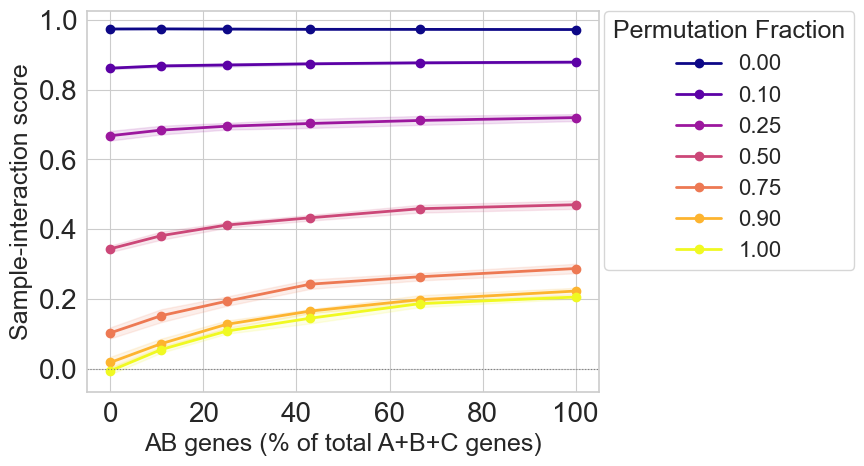

In [17]:
cmap1f = plt.cm.plasma
colors1f = [cmap1f(i / (len(PERM_FRACS_1C) - 1)) for i in range(len(PERM_FRACS_1C))]

fig, ax = plt.subplots(figsize=(9, 5))

for i, frac in enumerate(PERM_FRACS_1C):
    sub = df1f[df1f["perm_frac_b"] == frac].copy()
    sub["pct"] = sub["n_genes_AB"] / (N_GENES_1F * 2 + N_BG_1F) * 100
    g = sub.groupby("pct")["global_score"]
    m, s = g.mean(), g.std()
    ax.plot(m.index, m, "o-", color=colors1f[i], lw=2, label=f"{frac:.2f}")
    ax.fill_between(m.index, m - s, m + s, alpha=0.12, color=colors1f[i])

ax.axhline(0, color="gray", ls=":", lw=0.8)
ax.set_xlabel("AB genes (% of total A+B+C genes)")
ax.set_ylabel("Sample-interaction score")
# ax.set_title("Sample-interaction score as function of co-encoding genes ratio")
legend = ax.legend(fontsize=16, title="Permutation Fraction", title_fontsize=18,
                   loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "03_scenario1f.png"), dpi=150, bbox_inches="tight")
plt.show()

In [18]:
rows1f_perm1 = []
for n_ab in tqdm(AB_VALUES_1F, desc="n_ab"):
    for seed in range(N_SEEDS_1F):
        adata = simulate_cyclic_processes(
            N_CELLS, N_GENES_1F, N_GENES_1F, n_ab,
            n_genes_background=N_BG_1F,
            noise=0.1, seed=seed,
            perm_frac_b=1.0,
        )
        run_crisp(adata)
        la = adata.obs["label_a"].values
        lb = adata.obs["label_b"].values
        rows1f_perm1.append({
            "n_genes_AB":   n_ab,
            "seed":         seed,
            "global_score": adata.uns[GLOBAL_SCORE_KEY],
            "circ_reg":     circular_regression_global(la, lb),
        })

df1f_perm1 = pd.DataFrame(rows1f_perm1)
df1f_perm1.groupby("n_genes_AB")[["global_score", "circ_reg"]].agg(["mean", "std"]).round(3)

n_ab:   0%|          | 0/6 [00:00<?, ?it/s]

global_score        circ_reg       
                   mean    std     mean    std
n_genes_AB                                    
0                -0.006  0.010    0.017  0.017
22                0.055  0.009    0.019  0.018
50                0.108  0.008    0.021  0.017
86                0.145  0.015    0.019  0.017
133               0.187  0.010    0.019  0.021
200               0.205  0.005    0.019  0.019

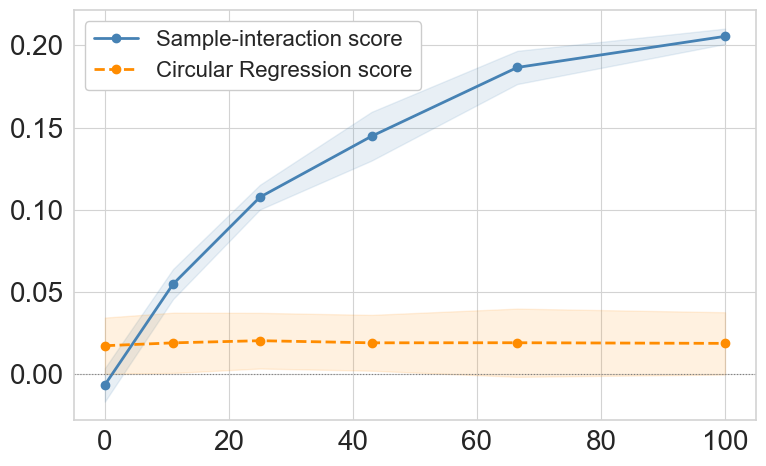

In [19]:
fig, ax = plt.subplots(figsize=(8, 5), facecolor="white")
ax.set_facecolor("white")
for spine in ax.spines.values():
    spine.set_edgecolor("lightgray")
    spine.set_linewidth(1.2)
ax.grid(True, color="lightgray", linewidth=0.8)
ax.set_axisbelow(True)

for col, label, color, ls in [
    ("global_score", "Sample-interaction score", "steelblue", "-"),
    ("circ_reg",     "Circular Regression score",     "darkorange", "--"),
]:
    df1f_perm1["pct"] = df1f_perm1["n_genes_AB"] / (N_GENES_1F * 2 + N_BG_1F) * 100
    g = df1f_perm1.groupby("pct")[col]
    m, s = g.mean(), g.std()
    ax.plot(m.index, m, color=color, lw=2, ls=ls, marker="o", label=label)
    ax.fill_between(m.index, m - s, m + s, alpha=0.12, color=color)

ax.axhline(0, color="gray", ls=":", lw=0.8)
# ax.set_xlabel("AB genes (% of total A+B+C genes)")
# ax.set_ylabel("Sample-interaction score")
# ax.set_title("Sample-interaction score and baseline as function of co-encoding genes ratio")
ax.legend(fontsize=16, frameon=True, facecolor="white", framealpha=1.0)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "03b_scenario1f_perm1.png"), dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

/tmp/ipykernel_2111787/1327584546.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


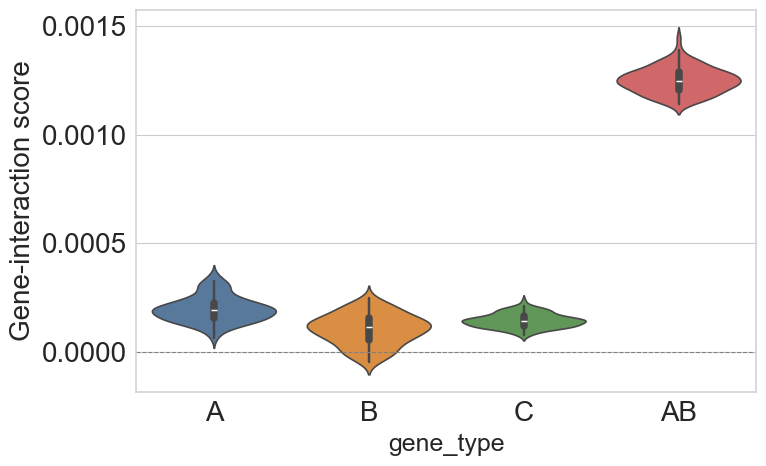

In [20]:
# Gene-contribution violin: 100A | 100B | 100C | 100AB, perm_frac_b=1.0
adata_contrib = simulate_cyclic_processes(
    N_CELLS, 100, 100, 100,
    n_genes_background=100,
    noise=0.1, seed=0,
    perm_frac_b=1.0,
)
crisp.encode_circular(adata_contrib, "label_a", obsm_key="sig_a")
crisp.encode_circular(adata_contrib, "label_b", obsm_key="sig_b")
with _quiet():
    crisp.compute_projection_similarity(adata_contrib, "sig_a", "sig_b", metric_A="knn", metric_B="knn", store_projections=True)

mean_contrib   = adata_contrib.var["proj_pearson_gene_contrib"].values
gene_type_contrib = adata_contrib.var["gene_type"].values

df_contrib = pd.DataFrame({
    "mean_contrib": mean_contrib,
    "gene_type":    gene_type_contrib,
})

fig, ax = plt.subplots(figsize=(8, 5), facecolor="white")
_style_ax(ax)

palette = dict(zip(gene_labels, gene_colors))
sns.violinplot(
    data=df_contrib, x="gene_type", y="mean_contrib",
    order=gene_labels, palette=palette,
    inner="box", linewidth=1.2, ax=ax,
)
ax.axhline(0, color="gray", lw=0.8, ls="--")
# ax.set_xlabel("Gene type", fontsize=21)
ax.set_ylabel("Gene-interaction score", fontsize=20)
# ax.set_title("Gene-interaction score by category",fontsize=20,
# )
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "03c_gene_contrib_violin.png"),
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

In [21]:
PERM_FRACS_AB100 = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]

rows_perm_ab100 = []
for pf in tqdm(PERM_FRACS_AB100, desc="perm_frac_b"):
    for seed in range(N_SEEDS_1F):
        adata = simulate_cyclic_processes(
            N_CELLS, 100, 100, 0,
            n_genes_background=0,
            noise=0.1, seed=seed,
            perm_frac_b=pf,
        )
        run_crisp(adata)
        la = adata.obs["label_a"].values
        lb = adata.obs["label_b"].values
        rows_perm_ab100.append({
            "perm_frac_b":  pf,
            "seed":         seed,
            "global_score": adata.uns[GLOBAL_SCORE_KEY],
            "circ_reg":     circular_regression_global(la, lb),
        })

df_perm_ab100 = pd.DataFrame(rows_perm_ab100)
df_perm_ab100.groupby("perm_frac_b")[["global_score", "circ_reg"]].agg(["mean", "std"]).round(3)

perm_frac_b:   0%|          | 0/7 [00:00<?, ?it/s]

global_score        circ_reg       
                    mean    std     mean    std
perm_frac_b                                    
0.00               0.974  0.001    0.990  0.001
0.10               0.862  0.003    0.894  0.003
0.25               0.668  0.014    0.740  0.012
0.50               0.344  0.009    0.491  0.010
0.75               0.102  0.016    0.253  0.023
0.90               0.018  0.016    0.102  0.023
1.00              -0.006  0.010    0.017  0.017

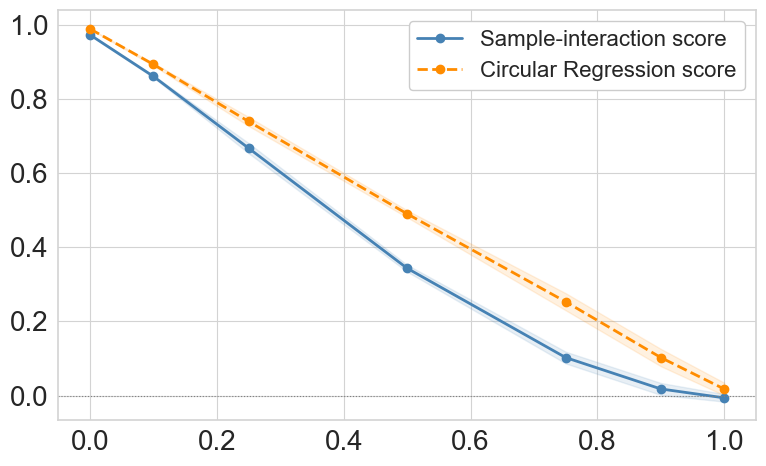

In [22]:
fig, ax = plt.subplots(figsize=(8, 5), facecolor="white")
ax.set_facecolor("white")
for spine in ax.spines.values():
    spine.set_edgecolor("lightgray")
    spine.set_linewidth(1.2)
ax.grid(True, color="lightgray", linewidth=0.8)
ax.set_axisbelow(True)

for col, label, color, ls in [
    ("global_score", "Sample-interaction score", "steelblue", "-"),
    ("circ_reg",     "Circular Regression score", "darkorange", "--"),
]:
    g = df_perm_ab100.groupby("perm_frac_b")[col]
    m, s = g.mean(), g.std()
    ax.plot(m.index, m, color=color, lw=2, ls=ls, marker="o", label=label)
    ax.fill_between(m.index, m - s, m + s, alpha=0.12, color=color)

ax.axhline(0, color="gray", ls=":", lw=0.8)
# ax.set_xlabel("Permutation fraction")
# ax.set_ylabel("Score")
# ax.set_title("Sample-interaction score as function of permutation fraction", pad=20)
ax.legend(fontsize=16, frameon=True, facecolor="white", framealpha=1.0)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "03c_score_vs_perm_ab100.png"), dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

---
## Cell score benchmark



In [23]:
from sklearn.metrics import adjusted_rand_score
def _circular_regression_residuals(label_a, label_b):
    """Per-cell residual from circular regression label_b = label_a + phi."""
    phi_hat = np.arctan2(np.mean(np.sin(label_b - label_a)),
                         np.mean(np.cos(label_b - label_a)))
    return 1 - np.cos(label_b - label_a - phi_hat)  # in [0, 2]; 0 = perfect fit



In [24]:
N_BG_VALUES_C = [0, 50, 100]
PERM_VALUES_C = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
N_SEEDS_C     = 5

rows_c = []
for n_bg in tqdm(N_BG_VALUES_C, desc="n_background"):
    for pf in PERM_VALUES_C:
        for seed in range(N_SEEDS_C):
            adata = simulate_cyclic_processes(
                N_CELLS, 100, 100, 0,
                n_genes_background=n_bg,
                noise=0.1, seed=seed,
                perm_frac_b=pf,
            )

            crisp.encode_circular(adata, "label_a", obsm_key="sig_a")
            crisp.encode_circular(adata, "label_b", obsm_key="sig_b")
            with _quiet():
                crisp.compute_projection_similarity(adata, "sig_a", "sig_b", metric_A="knn", metric_B="knn")

            permuted = adata.obs["permuted"].values.astype(bool)
            if permuted.sum() == 0 or (~permuted).sum() == 0:
                continue

            y  = (~permuted).astype(int)
            la = adata.obs["label_a"].values
            lb = adata.obs["label_b"].values

            cell_scores = adata.obs[CELL_SCORE_KEY].values.reshape(-1, 1)
            ari_proj = adjusted_rand_score(
                y, KMeans(n_clusters=2, n_init=10, random_state=0).fit(cell_scores).labels_
            )

            residuals = _circular_regression_residuals(la, lb).reshape(-1, 1)
            ari_cr = adjusted_rand_score(
                y, KMeans(n_clusters=2, n_init=10, random_state=0).fit(residuals).labels_
            )

            rows_c.append({"n_background": n_bg, "perm_frac_b": pf, "seed": seed,
                           "ari_crisp": ari_proj, "ari_cr": ari_cr})

df_c = pd.DataFrame(rows_c)
df_c.groupby(["n_background", "perm_frac_b"])[["ari_crisp", "ari_cr"]].mean().round(3)

n_background:   0%|          | 0/3 [00:00<?, ?it/s]

ari_crisp  ari_cr
n_background perm_frac_b                   
0            0.1              0.729   0.663
             0.2              0.690   0.596
             0.3              0.603   0.525
             0.4              0.481   0.413
             0.5              0.389   0.317
             0.6              0.268   0.213
             0.7              0.154   0.101
             0.8              0.076   0.052
             0.9              0.022   0.007
50           0.1              0.726   0.664
             0.2              0.679   0.605
             0.3              0.611   0.536
             0.4              0.484   0.403
             0.5              0.384   0.316
             0.6              0.270   0.201
             0.7              0.177   0.112
             0.8              0.069   0.059
             0.9              0.010   0.008
100          0.1              0.721   0.667
             0.2              0.681   0.594
             0.3              0.609   0.528
             0.4              0.479   0.406
             0.5              0.381   0.310
             0.6              0.265   0.207
             0.7              0.163   0.109
             0.8              0.070   0.058
             0.9              0.012   0.007

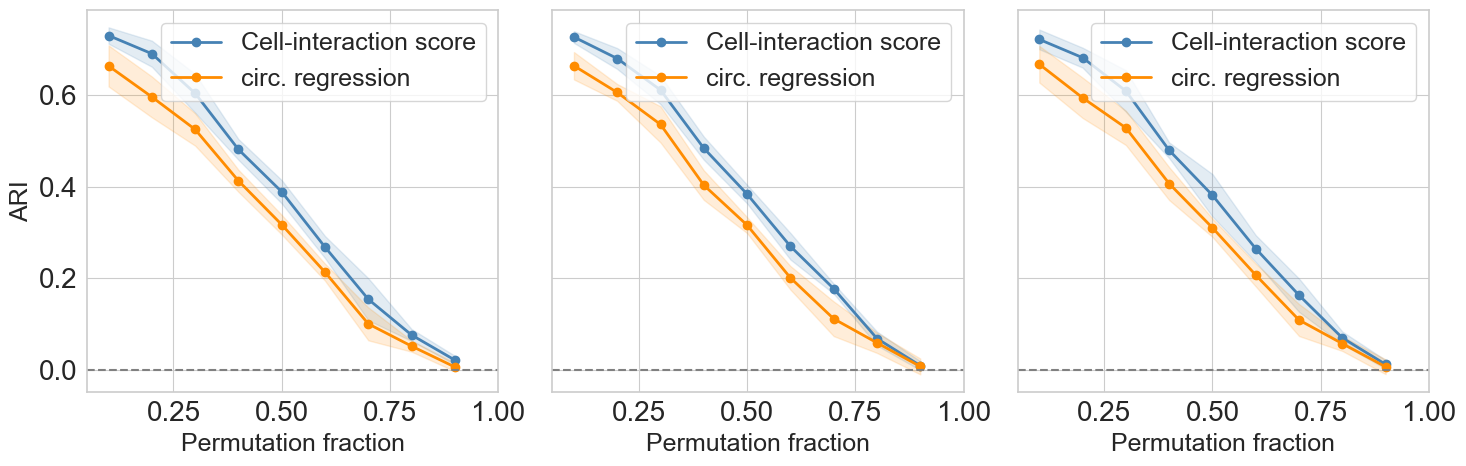

In [25]:
fig, axes = plt.subplots(1, len(N_BG_VALUES_C),
                         figsize=(5 * len(N_BG_VALUES_C), 5),
                         sharey=True, squeeze=False)
axes = axes[0]

for ax, n_bg in zip(axes, N_BG_VALUES_C):
    sub = df_c[df_c["n_background"] == n_bg]
    for col, label, color in [
        ("ari_crisp", "Cell-interaction score",          "steelblue"),
        ("ari_cr",      "circ. regression", "darkorange"),
    ]:
        g = sub.groupby("perm_frac_b")[col]
        m, s = g.mean(), g.std()
        ax.plot(m.index, m, "o-", color=color, lw=2, label=label)
        ax.fill_between(m.index, m - s, m + s, alpha=0.15, color=color)

    ax.axhline(0.0, color="gray", ls="--", lw=1.5)
    ax.set_xlabel("Permutation fraction")
    # ax.set_title(f"n_background = {n_bg}")
    ax.set_xlim([0.05, 1.0])
    ax.legend(fontsize=18)

axes[0].set_ylabel("ARI")
# plt.suptitle(
    # "ARI score comparison of cell-interaction score vs Circular Regression Residuals",
    # fontsize=22
# )
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "04_benchmark_c.png"), dpi=150, bbox_inches="tight")
plt.show()

In [26]:
LABEL_NOISE_VALUES = [0.0, 0.1, 0.2]
PERM_VALUES_LN     = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
N_SEEDS_LN         = 5

rows_ln = []
for ln in tqdm(LABEL_NOISE_VALUES, desc="label_noise"):
    for pf in PERM_VALUES_LN:
        for seed in range(N_SEEDS_LN):
            adata = simulate_cyclic_processes(
                N_CELLS, 100, 100, 0,
                n_genes_background=0,
                noise=0.1, seed=seed,
                perm_frac_b=pf,
                label_noise=ln,
            )

            crisp.encode_circular(adata, "label_a", obsm_key="sig_a")
            crisp.encode_circular(adata, "label_b", obsm_key="sig_b")
            with _quiet():
                crisp.compute_projection_similarity(adata, "sig_a", "sig_b", metric_A="knn", metric_B="knn")

            permuted = adata.obs["permuted"].values.astype(bool)
            if permuted.sum() == 0 or (~permuted).sum() == 0:
                continue

            y  = (~permuted).astype(int)
            la = adata.obs["label_a"].values
            lb = adata.obs["label_b"].values

            cell_scores = adata.obs[CELL_SCORE_KEY].values.reshape(-1, 1)
            ari_proj = adjusted_rand_score(
                y, KMeans(n_clusters=2, n_init=10, random_state=0).fit(cell_scores).labels_
            )

            residuals = _circular_regression_residuals(la, lb).reshape(-1, 1)
            ari_cr = adjusted_rand_score(
                y, KMeans(n_clusters=2, n_init=10, random_state=0).fit(residuals).labels_
            )

            rows_ln.append({"label_noise": ln, "perm_frac_b": pf, "seed": seed,
                            "ari_crisp": ari_proj, "ari_cr": ari_cr})

df_ln = pd.DataFrame(rows_ln)
df_ln.groupby(["label_noise", "perm_frac_b"])[["ari_crisp", "ari_cr"]].mean().round(3)

label_noise:   0%|          | 0/3 [00:00<?, ?it/s]

ari_crisp  ari_cr
label_noise perm_frac_b                   
0.0         0.1              0.739   0.674
            0.2              0.686   0.593
            0.3              0.594   0.534
            0.4              0.471   0.403
            0.5              0.370   0.306
            0.6              0.258   0.220
            0.7              0.169   0.110
            0.8              0.077   0.061
            0.9              0.011   0.007
0.1         0.1              0.729   0.663
            0.2              0.690   0.596
            0.3              0.603   0.525
            0.4              0.481   0.413
            0.5              0.389   0.317
            0.6              0.268   0.213
            0.7              0.154   0.101
            0.8              0.076   0.052
            0.9              0.022   0.007
0.2         0.1              0.720   0.663
            0.2              0.670   0.600
            0.3              0.569   0.513
            0.4              0.471   0.413
            0.5              0.368   0.315
            0.6              0.236   0.190
            0.7              0.149   0.103
            0.8              0.065   0.053
            0.9              0.005   0.014

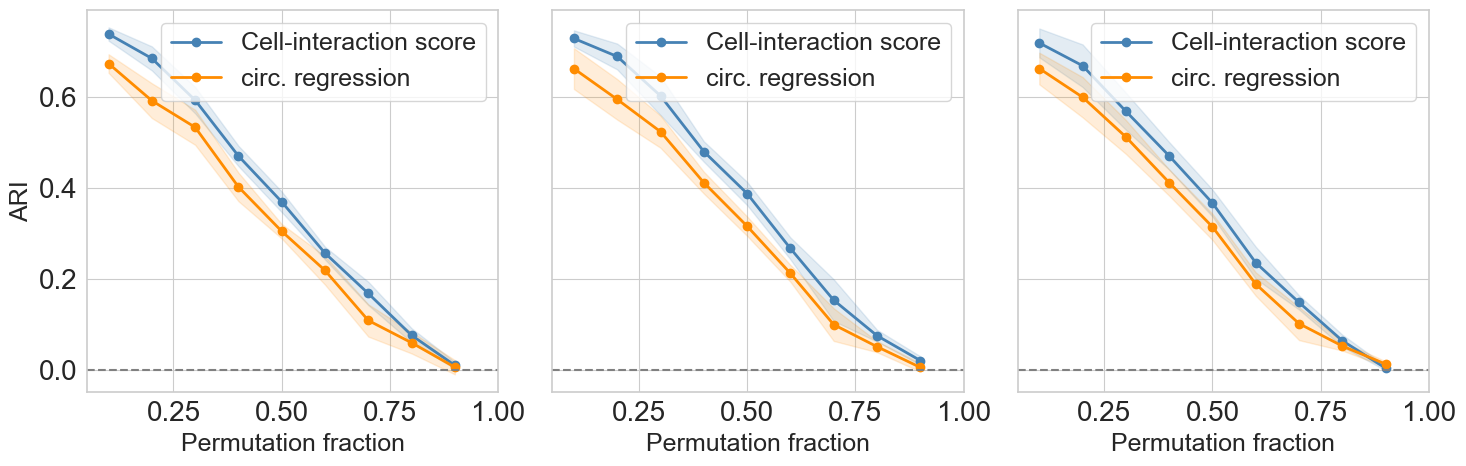

In [27]:
fig, axes = plt.subplots(1, len(LABEL_NOISE_VALUES),
                         figsize=(5 * len(LABEL_NOISE_VALUES), 5),
                         sharey=True, squeeze=False)
axes = axes[0]

for ax, ln in zip(axes, LABEL_NOISE_VALUES):
    sub = df_ln[df_ln["label_noise"] == ln]
    for col, label, color in [
        ("ari_crisp", "Cell-interaction score",       "steelblue"),
        ("ari_cr",      "circ. regression", "darkorange"),
    ]:
        g = sub.groupby("perm_frac_b")[col]
        m, s = g.mean(), g.std()
        ax.plot(m.index, m, "o-", color=color, lw=2, label=label)
        ax.fill_between(m.index, m - s, m + s, alpha=0.15, color=color)

    ax.axhline(0.0, color="gray", ls="--", lw=1.5)
    ax.set_xlabel("Permutation fraction")
    # ax.set_title(f"label_noise = {ln}")
    ax.set_xlim([0.05, 1.0])
    ax.legend(fontsize=18)

axes[0].set_ylabel("ARI")
# plt.suptitle(
    # "ARI: cell-interaction score vs Circular Regression — varying label noise\n"
    # ,
    # fontsize=22,
# )
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "04c_benchmark_label_noise.png"), dpi=150, bbox_inches="tight")
plt.show()

In [28]:
# Fix n_background, sweep n_genes_AB — one figure per n_bg setting
N_BG_FIXED_C2  = [0, 50, 100]
AB_VALUES_C2   = [0, 50, 100]
PERM_VALUES_C2 = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
N_SEEDS_C2     = 5

rows_c2 = []
for n_bg in tqdm(N_BG_FIXED_C2, desc="n_background"):
    for n_ab in AB_VALUES_C2:
        for pf in PERM_VALUES_C2:
            for seed in range(N_SEEDS_C2):
                adata = simulate_cyclic_processes(
                    N_CELLS, 100, 100, n_ab,
                    n_genes_background=n_bg,
                    noise=0.1, seed=seed,
                    perm_frac_b=pf,
                )
                crisp.encode_circular(adata, "label_a", obsm_key="sig_a")
                crisp.encode_circular(adata, "label_b", obsm_key="sig_b")
                with _quiet():
                    crisp.compute_projection_similarity(adata, "sig_a", "sig_b", metric_A="knn", metric_B="knn")

                permuted = adata.obs["permuted"].values.astype(bool)
                if permuted.sum() == 0 or (~permuted).sum() == 0:
                    continue

                y  = (~permuted).astype(int)
                la = adata.obs["label_a"].values
                lb = adata.obs["label_b"].values

                cell_scores = adata.obs[CELL_SCORE_KEY].values.reshape(-1, 1)
                ari_proj = adjusted_rand_score(
                    y, KMeans(n_clusters=2, n_init=10, random_state=0).fit(cell_scores).labels_
                )

                residuals = _circular_regression_residuals(la, lb).reshape(-1, 1)
                ari_cr = adjusted_rand_score(
                    y, KMeans(n_clusters=2, n_init=10, random_state=0).fit(residuals).labels_
                )

                rows_c2.append({
                    "n_background": n_bg,
                    "n_genes_AB":   n_ab,
                    "perm_frac_b":  pf,
                    "seed":         seed,
                    "ari_crisp":  ari_proj,
                    "ari_cr":       ari_cr,
                })

df_c2 = pd.DataFrame(rows_c2)
df_c2.groupby(["n_background", "n_genes_AB", "perm_frac_b"])[["ari_crisp", "ari_cr"]].mean().round(3)

n_background:   0%|          | 0/3 [00:00<?, ?it/s]

ari_crisp  ari_cr
n_background n_genes_AB perm_frac_b                   
0            0          0.1              0.729   0.663
                        0.2              0.690   0.596
                        0.3              0.603   0.525
                        0.4              0.481   0.413
                        0.5              0.389   0.317
...                                        ...     ...
100          100        0.5              0.381   0.311
                        0.6              0.270   0.209
                        0.7              0.162   0.104
                        0.8              0.065   0.053
                        0.9              0.014   0.011

[81 rows x 2 columns]

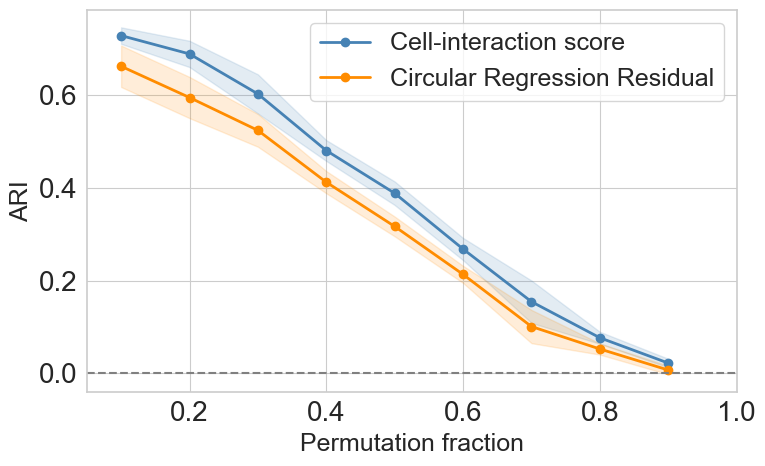

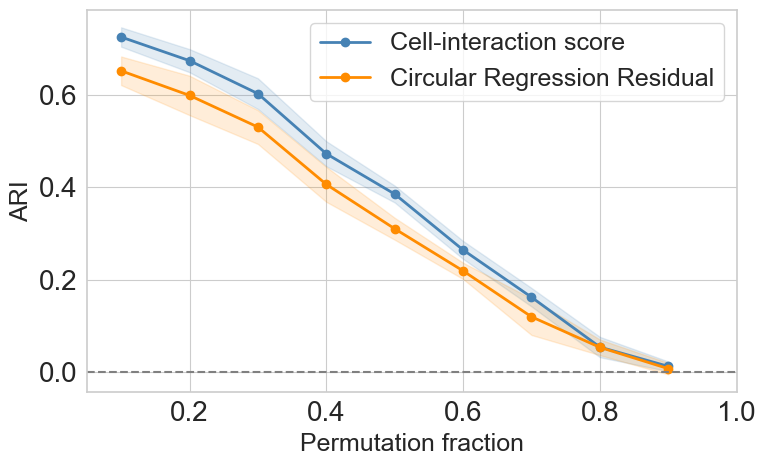

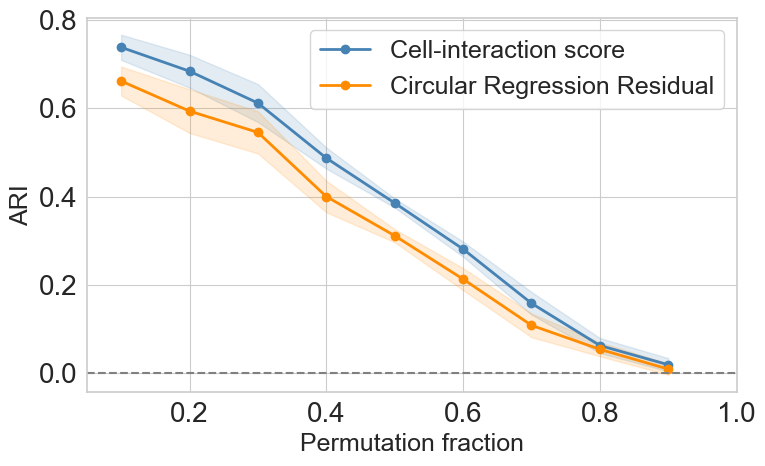

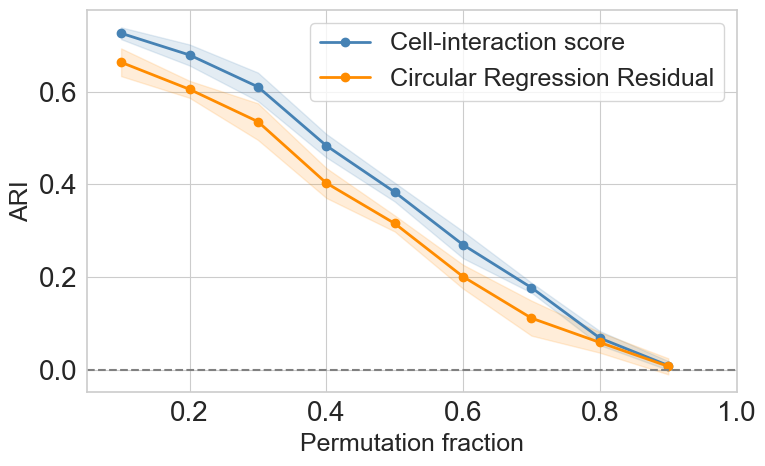

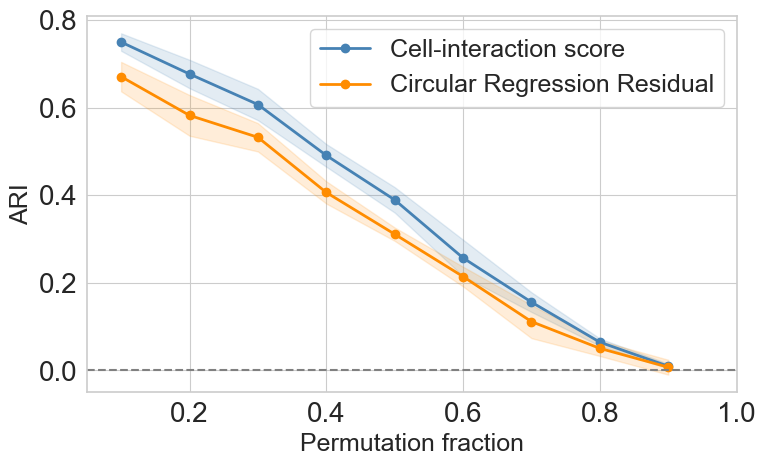

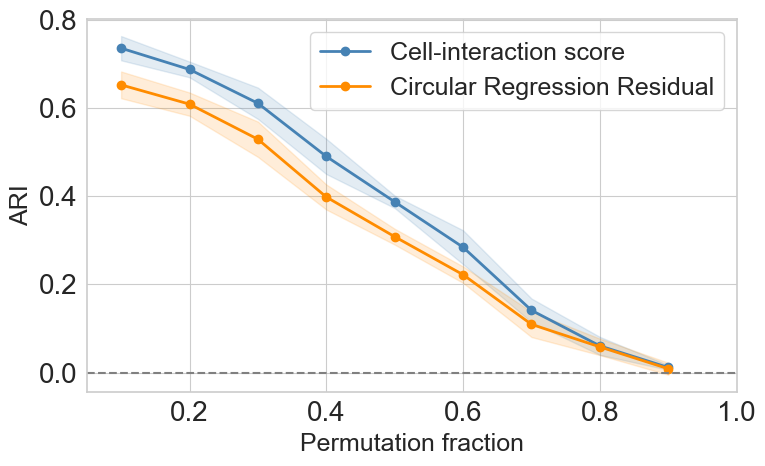

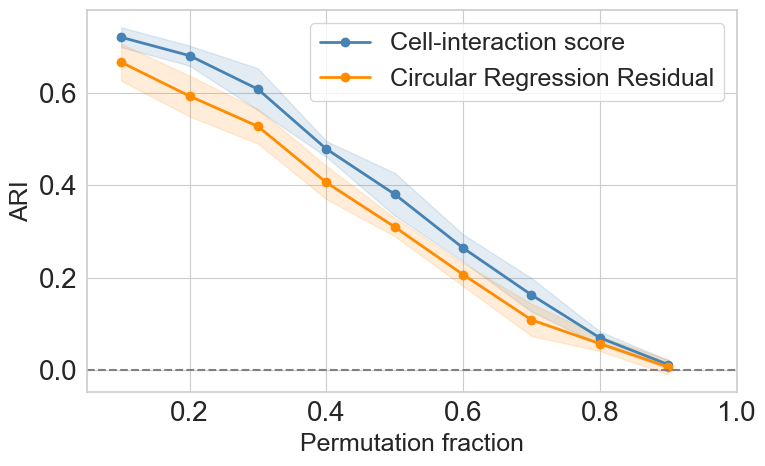

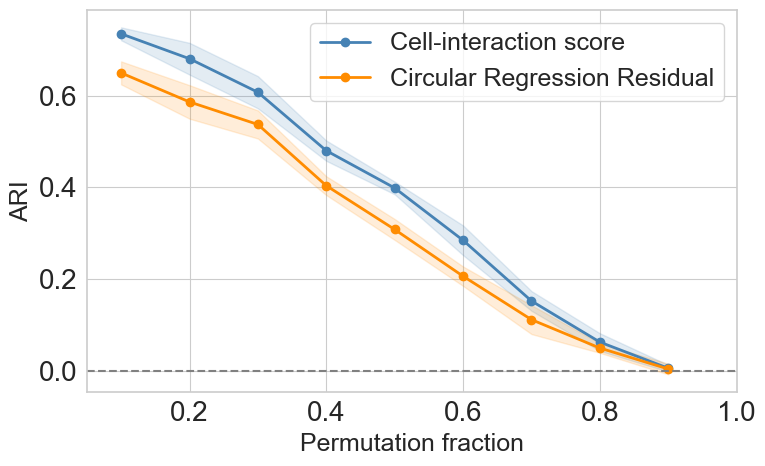

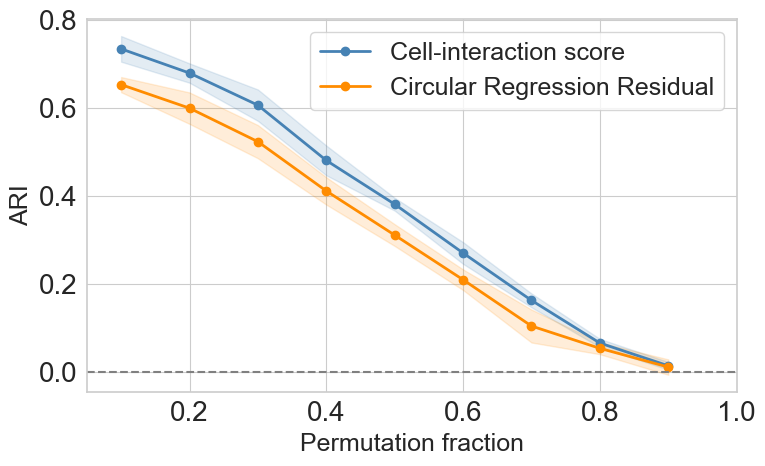

In [29]:
for n_bg in N_BG_FIXED_C2:
    for n_ab in AB_VALUES_C2:
        sub = df_c2[(df_c2["n_background"] == n_bg) & (df_c2["n_genes_AB"] == n_ab)]

        fig, ax = plt.subplots(figsize=(8, 5))

        for col, label, color in [
            ("ari_crisp", "Cell-interaction score", "steelblue"),
            ("ari_cr",      "Circular Regression Residual",  "darkorange"),
        ]:
            g = sub.groupby("perm_frac_b")[col]
            m, s = g.mean(), g.std()
            ax.plot(m.index, m, "o-", color=color, lw=2, label=label)
            ax.fill_between(m.index, m - s, m + s, alpha=0.15, color=color)

        ax.axhline(0.0, color="gray", ls="--", lw=1.5)
        ax.set_xlabel("Permutation fraction")
        ax.set_ylabel("ARI")
        # ax.set_title(
            # f"ARI: cell-interaction score vs Circular Regression\n"
        # )
        ax.set_xlim([0.05, 1.0])
        ax.legend(fontsize=18)
        plt.tight_layout()
        fname = f"04b_benchmark_bg{n_bg}_ab{n_ab}.png"
        plt.savefig(os.path.join(SAVE_DIR, fname), dpi=150, bbox_inches="tight")
        plt.show()

In [30]:
# Per-cell data: 100 A | 100 B | 100 AB, perm_frac_b=0.5
PERM_FRAC_BP = 0.3

adata_bp = simulate_cyclic_processes(
    N_CELLS, 100, 100, 100,
    n_genes_background=0,
    noise=0.1, seed=0,
    perm_frac_b=PERM_FRAC_BP,
)

crisp.encode_circular(adata_bp, "label_a", obsm_key="sig_a")
crisp.encode_circular(adata_bp, "label_b", obsm_key="sig_b")
with _quiet():
    crisp.compute_projection_similarity(adata_bp, "sig_a", "sig_b", metric_A="knn", metric_B="knn", store_projections=True)

la_bp       = adata_bp.obs["label_a"].values
lb_bp       = adata_bp.obs["label_b"].values
permuted_bp = adata_bp.obs["permuted"].values.astype(bool)

order   = ["non-permuted", "permuted"]
palette = {"non-permuted": "steelblue", "permuted": "crimson"}

bp_df = pd.DataFrame({
    "cell_score": adata_bp.obs[CELL_SCORE_KEY].values,
    "group":      np.where(permuted_bp, "permuted", "non-permuted"),
})

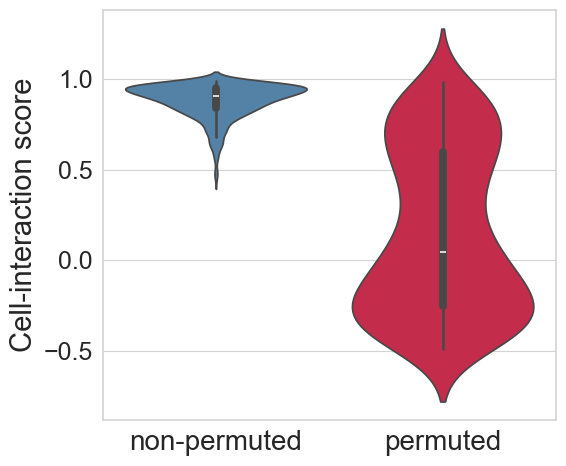

In [31]:
fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")
ax.set_facecolor("white")
for spine in ax.spines.values():
    spine.set_edgecolor("lightgray")
    spine.set_linewidth(1.2)
ax.grid(True, color="lightgray", linewidth=0.8)
# ax.set_axisbelow(True)

sns.violinplot(data=bp_df, x="group", y="cell_score",
               order=order, hue="group", palette=palette, legend=False, inner="box", ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Cell-interaction score", fontsize=21)
ax.tick_params(axis="x", labelsize=20)
ax.tick_params(axis="y", labelsize=18)

# plt.title(f"Cell-interaction score (permutation fraction = {PERM_FRAC_BP})", fontsize=24)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "06_violins.png"), dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

---
## Trivial partition check

Goal: show that obvious/trivial partitions of the data do **not** separate
interacting (non-permuted) from non-interacting (permuted) cells.
If crisp cell score achieves higher ARI than all trivial baselines,
it proves the score captures something beyond the dominant data structure.

Trivial baselines (K-Means k=2 on each):
- **label_a only** — clusters by phase of signal A
- **label_b only** — clusters by phase of signal B
- **PC1 of expression** — clusters by the dominant variance direction

In [32]:
def leiden_k2(adata):
    """Run Leiden with binary search on resolution until exactly 2 clusters."""
    lo, hi = 0.0, 5.0
    for _ in range(30):
        mid = (lo + hi) / 2
        with _quiet():
            sc.tl.leiden(adata, resolution=mid, flavor="igraph", n_iterations=2)
        n = adata.obs["leiden"].nunique()
        if n == 2:
            return mid, 2
        elif n < 2:
            lo = mid
        else:
            hi = mid
    return mid, adata.obs["leiden"].nunique()

PERM_VALUES_TRIV = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

rows_triv = []
for pf in tqdm(PERM_VALUES_TRIV, desc="perm_frac_b"):
    for seed in range(N_SEEDS):
        adata = simulate_cyclic_processes(
            N_CELLS, 100, 100, 0,
            n_genes_background=0,
            noise=0.1, seed=seed,
            perm_frac_b=pf,
        )
        crisp.encode_circular(adata, "label_a", obsm_key="sig_a")
        crisp.encode_circular(adata, "label_b", obsm_key="sig_b")
        with _quiet():
            crisp.compute_projection_similarity(adata, "sig_a", "sig_b", metric_A="knn", metric_B="knn")

        permuted = adata.obs["permuted"].values.astype(bool)
        if permuted.sum() == 0 or (~permuted).sum() == 0:
            continue

        y      = (~permuted).astype(int)
        X_expr = adata.X if not hasattr(adata.X, "toarray") else adata.X.toarray()

        cell_scores = adata.obs[CELL_SCORE_KEY].values.reshape(-1, 1)
        ari_proj = adjusted_rand_score(
            y, KMeans(n_clusters=2, n_init=10, random_state=0).fit(cell_scores).labels_
        )

        ari_km = adjusted_rand_score(
            y, KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_expr).labels_
        )

        with _quiet():
            sc.pp.pca(adata)
            sc.pp.neighbors(adata, n_neighbors=int(np.sqrt(N_CELLS)), use_rep="X_pca")
        res_found, n_clust = leiden_k2(adata)
        ari_leiden = adjusted_rand_score(y, adata.obs["leiden"].values)
        print(f"  perm_frac_b={pf:.1f}  seed={seed}  "
              f"n_clusters={n_clust}  resolution={res_found:.4f}")

        rows_triv.append({"perm_frac_b": pf, "seed": seed,
                          "n_clusters": n_clust, "resolution": res_found,
                          "ari_crisp": ari_proj,
                          "ari_km":      ari_km,
                          "ari_leiden":  ari_leiden})

df_triv = pd.DataFrame(rows_triv)
df_triv.groupby("perm_frac_b")[["ari_crisp", "ari_km", "ari_leiden", "n_clusters", "resolution"]].mean().round(3)

perm_frac_b:   0%|          | 0/9 [00:00<?, ?it/s]

  perm_frac_b=0.1  seed=0  n_clusters=2  resolution=0.0781
  perm_frac_b=0.1  seed=1  n_clusters=2  resolution=0.1172
  perm_frac_b=0.1  seed=2  n_clusters=2  resolution=0.0781
  perm_frac_b=0.1  seed=3  n_clusters=2  resolution=0.1172
  perm_frac_b=0.1  seed=4  n_clusters=2  resolution=0.0781
  perm_frac_b=0.2  seed=0  n_clusters=2  resolution=0.0684
  perm_frac_b=0.2  seed=1  n_clusters=2  resolution=0.0781
  perm_frac_b=0.2  seed=2  n_clusters=2  resolution=0.0488
  perm_frac_b=0.2  seed=3  n_clusters=2  resolution=0.0586
  perm_frac_b=0.2  seed=4  n_clusters=2  resolution=0.0391
  perm_frac_b=0.3  seed=0  n_clusters=2  resolution=0.0586
  perm_frac_b=0.3  seed=1  n_clusters=2  resolution=0.0488
  perm_frac_b=0.3  seed=2  n_clusters=2  resolution=0.0488
  perm_frac_b=0.3  seed=3  n_clusters=2  resolution=0.0391
  perm_frac_b=0.3  seed=4  n_clusters=2  resolution=0.0391
  perm_frac_b=0.4  seed=0  n_clusters=2  resolution=0.0488
  perm_frac_b=0.4  seed=1  n_clusters=2  resolution=0.04

,ari_crisp,ari_km,ari_leiden,n_clusters,resolution
perm_frac_b,,,,,
0.1,0.729,-0.001,-0.050,2.0,0.094
0.2,0.690,-0.002,-0.046,2.0,0.059
0.3,0.603,0.000,-0.030,2.0,0.047
0.4,0.481,-0.000,0.021,2.0,0.055
0.5,0.389,-0.000,0.058,2.0,0.053
0.6,0.268,0.001,0.117,2.0,0.059
0.7,0.154,0.000,0.128,2.0,0.062
0.8,0.076,0.001,0.005,2.0,0.074
0.9,0.022,0.002,0.027,2.0,0.078


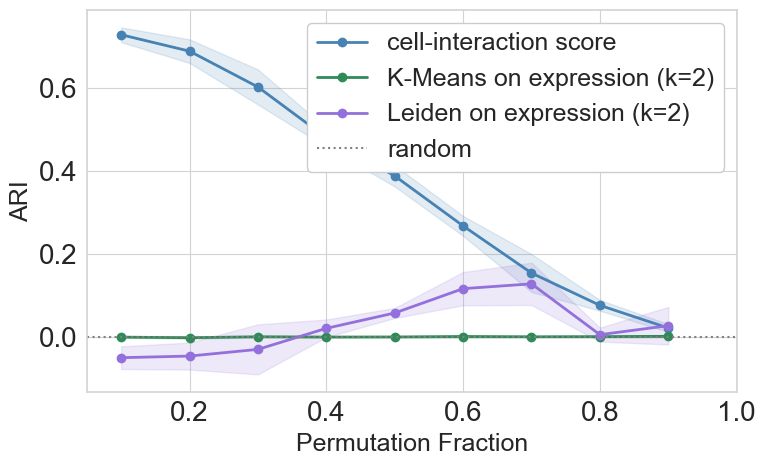

In [33]:
fig, ax = plt.subplots(figsize=(8, 5), facecolor="white")
ax.set_facecolor("white")
for spine in ax.spines.values():
    spine.set_edgecolor("lightgray")
    spine.set_linewidth(1.2)
ax.grid(True, color="lightgray", linewidth=0.8)
ax.set_axisbelow(True)

for col, label, color in [
    ("ari_crisp", "cell-interaction score", "steelblue"),
    ("ari_km",      "K-Means on expression (k=2)", "seagreen"),
    ("ari_leiden",  "Leiden on expression (k=2)", "mediumpurple"),
]:
    g = df_triv.groupby("perm_frac_b")[col]
    m, s = g.mean(), g.std()
    ax.plot(m.index, m, "o-", color=color, lw=2, label=label)
    ax.fill_between(m.index, m - s, m + s, alpha=0.15, color=color)

ax.axhline(0.0, color="gray", ls=":", lw=1.5, label="random")
ax.set_xlabel("Permutation Fraction")
ax.set_ylabel("ARI")
# ax.set_title(
    # "ARI of cell-interaction score and trivial partitions of data"

# )
ax.set_xlim([0.05, 1.0])
ax.legend(fontsize=18, frameon=True, facecolor="white", framealpha=1.0)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "08_trivial_partition.png"), dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

In [34]:
# Combined benchmark: cell score vs circular regression vs 2 trivial baselines
# Single loop so all metrics are evaluated on identical simulations.
# Settings: 100A | 100B | 0AB | 0BG, sweep perm_frac_b.
PERM_VALUES_CMB = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
N_SEEDS_CMB = 5

rows_cmb = []
for pf in tqdm(PERM_VALUES_CMB, desc="perm_frac_b"):
    for seed in range(N_SEEDS_CMB):
        adata = simulate_cyclic_processes(
            N_CELLS, 100, 100, 0,
            n_genes_background=0,
            noise=0.1, seed=seed,
            perm_frac_b=pf,
        )
        crisp.encode_circular(adata, "label_a", obsm_key="sig_a")
        crisp.encode_circular(adata, "label_b", obsm_key="sig_b")
        with _quiet():
            crisp.compute_projection_similarity(adata, "sig_a", "sig_b", metric_A="knn", metric_B="knn")

        permuted = adata.obs["permuted"].values.astype(bool)
        if permuted.sum() == 0 or (~permuted).sum() == 0:
            continue
        y      = (~permuted).astype(int)
        la     = adata.obs["label_a"].values
        lb     = adata.obs["label_b"].values
        X_expr = adata.X if not hasattr(adata.X, "toarray") else adata.X.toarray()

        ari_proj = adjusted_rand_score(
            y, KMeans(n_clusters=2, n_init=10, random_state=0)
               .fit(adata.obs[CELL_SCORE_KEY].values.reshape(-1, 1)).labels_
        )
        ari_cr = adjusted_rand_score(
            y, KMeans(n_clusters=2, n_init=10, random_state=0)
               .fit(_circular_regression_residuals(la, lb).reshape(-1, 1)).labels_
        )
        ari_km = adjusted_rand_score(
            y, KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_expr).labels_
        )
        with _quiet():
            sc.pp.pca(adata)
            sc.pp.neighbors(adata, n_neighbors=int(np.sqrt(N_CELLS)), use_rep="X_pca")
        _, _ = leiden_k2(adata)
        ari_leiden = adjusted_rand_score(y, adata.obs["leiden"].values)

        rows_cmb.append({
            "perm_frac_b": pf, "seed": seed,
            "ari_crisp": ari_proj,
            "ari_cr":      ari_cr,
            "ari_km":      ari_km,
            "ari_leiden":  ari_leiden,
        })

df_cmb = pd.DataFrame(rows_cmb)
df_cmb.groupby("perm_frac_b")[["ari_crisp", "ari_cr", "ari_km", "ari_leiden"]].mean().round(3)

perm_frac_b:   0%|          | 0/9 [00:00<?, ?it/s]

,ari_crisp,ari_cr,ari_km,ari_leiden
perm_frac_b,,,,
0.1,0.729,0.663,-0.001,-0.050
0.2,0.690,0.596,-0.002,-0.046
0.3,0.603,0.525,0.000,-0.030
0.4,0.481,0.413,-0.000,0.021
0.5,0.389,0.317,-0.000,0.058
0.6,0.268,0.213,0.001,0.117
0.7,0.154,0.101,0.000,0.128
0.8,0.076,0.052,0.001,0.005
0.9,0.022,0.007,0.002,0.027


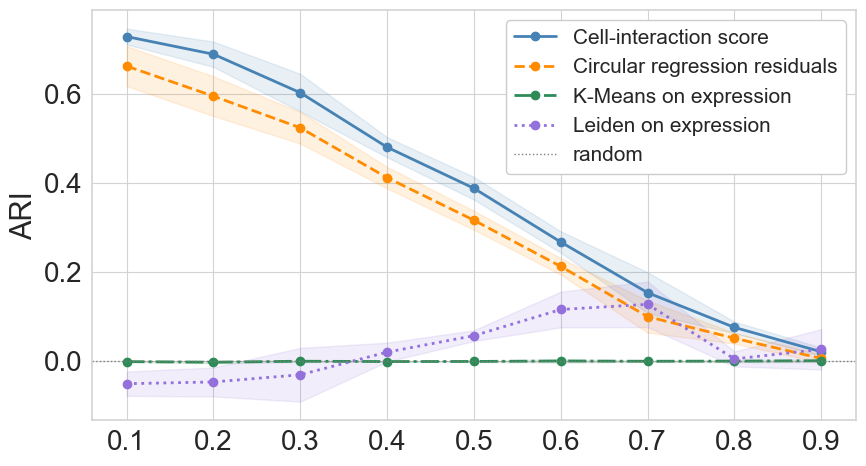

In [35]:
fig, ax = plt.subplots(figsize=(9, 5), facecolor="white")
ax.set_facecolor("white")
for spine in ax.spines.values():
    spine.set_edgecolor("lightgray")
    spine.set_linewidth(1.2)
ax.grid(True, color="lightgray", linewidth=0.8)
ax.set_axisbelow(True)

for col, label, color, ls in [
    ("ari_crisp", "Cell-interaction score",          "steelblue",    "-"),
    ("ari_cr",      "Circular regression residuals",  "darkorange",   "--"),
    ("ari_km",      "K-Means on expression",          "seagreen",     "-."),
    ("ari_leiden",  "Leiden on expression",           "mediumpurple", ":"),
]:
    g = df_cmb.groupby("perm_frac_b")[col]
    m, s = g.mean(), g.std()
    ax.plot(m.index, m, color=color, lw=2, ls=ls, marker="o", label=label)
    ax.fill_between(m.index, m - s, m + s, alpha=0.12, color=color)

ax.axhline(0.0, color="gray", ls=":", lw=1.0, label="random")
# ax.set_xlabel("Permutation fraction", fontsize=21)
ax.set_ylabel("ARI", fontsize=21)
# ax.set_title("Cell-interaction score and baselines ARI scores", fontsize=20)
ax.legend(fontsize=15, frameon=True, facecolor="white", framealpha=1.0)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "07_combined_benchmark.png"), dpi=150, bbox_inches="tight", facecolor="white")
plt.show()